# 03 · Información externa: qué hay, cuándo se conoce y qué parece aportar

**Punto de partida.** El notebook 02 encontró que casi todo el error del MDA en Monclova está en la componente de energía, y que esa componente es un precio **nacional**: la misma en todos los nodos del país. Eso cambia la pregunta. No se busca qué pasa en Monclova, sino qué información, conocida el día anterior, podría anticipar una sorpresa en el precio nacional de la energía.

**Qué hace este notebook:**

1. Reúne las fuentes candidatas y fija **cuándo** se conoce cada dato en la práctica. Esto es lo más delicado: una variable que en la tabla parece del día anterior, pero que en realidad se publicó después, mete información del futuro sin que nadie lo note. La regla es una sola: el pronóstico del día *d* se emite hacia el mediodía de *d−1*, y una variable vale solo si su valor ya existía en ese momento.
2. Explora cada fuente con el mismo procedimiento, para ver si se relaciona con lo que se pronostica: la diferencia MTR − MDA.
3. Resume qué fuentes tienen alguna señal estable, que es lo que el notebook 07 pondrá a prueba dentro de un modelo.

**El orden de las fuentes** va de lo más obvio a lo más indirecto, y es también el orden en que se fueron planteando:

| Familia | Fuentes | Secciones |
|---|---|---|
| El costo del combustible | precios del gas, petróleo y tipo de cambio; inventarios de gas | 2.1–2.2 |
| La región vecina y el clima local | demanda pronosticada de Texas; clima de Monclova, Monterrey y Texas | 2.3–2.5 |
| El estado del sistema y el calendario | alertas de CENACE; vacaciones | 2.6–2.7 |
| Lo que ya pasó ayer, o se sabe el día anterior | operación real y precio en tiempo real de Texas; clima de los grandes centros de carga del país | 2.8–2.10 |
| La red de transmisión y el pasado | qué parte del error es local; congestión en la red; clima del país como serie; días parecidos del pasado | 2.11–2.14 |

Después de cada familia se escribe qué se esperaba, qué se ve y qué implica. Las fuentes de las últimas dos familias se agregaron después de ver que las primeras no servían. La sección 4 cuenta ese razonamiento.

**Las fuentes de la primera ronda y cuándo se dan por conocidas:**

| Fuente | Qué aporta | Cuándo se da por conocida |
|---|---|---|
| FRED: Henry Hub, WTI, Brent, diésel del Golfo, USD/MXN | costo del combustible y su conversión a pesos | último dato con fecha ≤ *d−2*. Como prueba de sensibilidad, ≤ *d−8*, por si la publicación se retrasa |
| EIA: inventarios semanales de gas | escasez de gas hacia adelante | la semana que cierra en viernes se publica el jueves siguiente: periodo + 6 días, más 2 de margen |
| EIA-930: pronóstico de demanda de Texas (ERCOT) | demanda en Texas, interconectado con el noreste | se trata como pronóstico del día anterior. **Es un supuesto**: EIA no documenta la hora exacta |
| Open-Meteo, pronósticos anteriores, zona Monclova–Frontera | calor, radiación, nubosidad, viento | pronóstico emitido al menos 48 h antes de cada hora, siempre antes del mediodía de *d−1* |

Dos fuentes quedaron fuera. Los **futuros de gas de EIA** terminan el 5 de abril de 2024. El **archivo de "pronósticos históricos" de Open-Meteo**, que se usó en una primera versión, es demasiado optimista: está armado con corridas muy cercanas a la hora del pronóstico, así que se parece más a lo observado que a lo que se sabía el día anterior. El archivo de corridas previas es la forma honesta de tener "el pronóstico que existía".

In [1]:
import os
for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'): os.environ[k] = '1'   # evita sobresuscripción en procesos paralelos
import sys, warnings, time, pickle, re
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from pml import plotstyle as ps
ps.aplicar()
FIG = ROOT / 'reports/figures'; REP = ROOT / 'reports'

# Contexto con todos los datos: precios de Monclova y cada fuente externa, ya con su regla de disponibilidad
from pml import exog, features2 as f2
c = f2.cargar_ctx()
print('días de modelado:', c.dias.min().date(), '→', c.dias.max().date())
from pml import explora as ex
# Todas las variables externas candidatas (grupos G4 a G12) y los tres objetivos contra los que se comparan:
# el nivel del MTR, la diferencia MTR − MDA (lo que pronosticamos) y su tamaño |MTR − MDA|
GR_EX = ['G4', 'G5', 'G6', 'G6g', 'G6e', 'G7v', 'G8', 'G9', 'G10', 'G11', 'G12']
FX, GX = f2.construir(c, GR_EX); O = ex.objetivos(c)
def explorar(cols, clave, titulo, unidad, archivo):
    """Serie, quintiles, correlaciones por periodo y rezagos de una fuente."""
    Q = ex.panel(FX, O, cols, clave, titulo, unidad, FIG / archivo, plt, ps)
    print('promedios por grupo de la feature clave (feb–dic 2024):'); display(Q)
    print('correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:'); display(ex.correlaciones(FX, O, cols))
    print('correlación con la diferencia si la feature llegara k días más tarde:'); display(ex.rezagos(FX, O, cols))

días de modelado: 2024-02-05 → 2025-06-30


## 1. Cobertura y huecos

In [2]:
# Inventario: cuántas observaciones tiene cada fuente, desde cuándo y si tiene huecos en el periodo de modelado
display(pd.DataFrame({k: (len(s), s.index.min().date(), s.index.max().date()) for k, s in c.fred.items()}, index=['observaciones', 'inicio', 'fin']).T)
print('inventarios de gas:', len(c.inv), 'semanas,', c.inv.index.min().date(), '→', c.inv.index.max().date())
print('clima de la zona, NaN desde', f2.TRAIN_START.date(), ':', {k: int(v.loc[f2.TRAIN_START:].isna().sum().sum()) for k, v in c.W.items()})
print('ERCOT DF, NaN en el periodo:', int(c.ercot.loc[f2.TRAIN_START:'2025-06-30'].isna().sum().sum()))
print('futuros de gas EIA: último dato', exog.futuros_gas().index.max().date())
print('Monterrey y Texas, NaN:', {p: int(w['temperature_2m'].loc[f2.TRAIN_START:'2025-06-30'].isna().sum().sum()) for p, w in c.Wext.items()})
print('clima nacional (5 puntos), NaN:', {p: int(w['temperature_2m'].loc[f2.TRAIN_START:'2025-06-30'].isna().sum().sum()) for p, w in c.Wnac[2].items()})
print('EIA-930 de ERCOT, NaN:', {k: int(v.loc[f2.TRAIN_START:'2025-06-30'].isna().sum().sum()) for k, v in c.e930.items()})
print('precio RT de ERCOT:', c.rt.index.min(), '→', c.rt.index.max(), '| horas sin dato en el periodo:',
      int(c.rt.loc[f2.TRAIN_START:'2025-06-30'].isna().any(axis=1).sum()))
print('índice nacional de clima (14 puntos), NaN:', {k: int(w['temperature_2m'].loc[f2.TRAIN_START:'2025-06-30'].isna().sum().sum()) for k, w in c.Wi.items()})
print('nodos de la red:', sum(len(v) for v in __import__('pml.red', fromlist=['x']).GRUPOS_RED.values()), 'en', len(c.red['MDA']), 'corredores; días con MDA:', len(c.red['MDA']['centro']))

,observaciones,inicio,fin
hh_spot,415,2023-11-01,2025-06-30
wti,412,2023-11-01,2025-06-30
brent,419,2023-11-01,2025-06-30
usdmxn,415,2023-11-01,2025-06-30
diesel_golfo,413,2023-11-01,2025-06-30
gasolina_ny,413,2023-11-01,2025-06-30
combustoleo_ny,413,2023-11-01,2025-06-30


inventarios de gas: 87 semanas, 2023-11-03 → 2025-06-27
clima de la zona, NaN desde 2024-02-05 : {'temperature_2m': 0, 'apparent_temperature': 0, 'relative_humidity_2m': 0, 'dew_point_2m': 0, 'cloud_cover': 0, 'shortwave_radiation': 1, 'direct_normal_irradiance': 1, 'wind_speed_10m': 0, 'precipitation': 1, 'surface_pressure': 0}
ERCOT DF, NaN en el periodo: 0
futuros de gas EIA: último dato 2024-04-05
Monterrey y Texas, NaN: {'Monterrey': 0, 'SanAntonio': 0, 'Midland': 0}
clima nacional (5 puntos), NaN: {'CDMX': 0, 'Guadalajara': 0, 'Hermosillo': 0, 'Juchitan': 0, 'Reynosa': 0}
EIA-930 de ERCOT, NaN: {'demanda': 0, 'eolica': 0, 'solar': 4, 'gas': 0, 'intercambio_mx': 1}
precio RT de ERCOT: 2023-01-01 00:00:00 → 2025-12-31 23:00:00 | horas sin dato en el periodo: 0
índice nacional de clima (14 puntos), NaN: {0: 0, 2: 0, 3: 0, 4: 0}
nodos de la red: 31 en 10 corredores; días con MDA: 561


Salió un problema práctico. La temperatura de `previous_day2` tiene un hueco del 5 al 19 de enero de 2024, y las demás variables meteorológicas empiezan el 20 de enero. No se rellena a mano un pronóstico que no existió, así que **todos los modelos entrenan desde el 2024-02-05**, el primer día con dos semanas de historia meteorológica completa.

Otra limitación: FRED entrega la última versión de cada serie, no la que existía cada día. En precios spot las revisiones son mínimas, pero conviene tenerlo presente.

## 2. Cómo se explora cada fuente

Una correlación sola engaña, así que cada fuente pasa por la misma revisión. Se mide su relación con tres cosas distintas:

- **El nivel del MTR:** si la variable acompaña al precio. El MDA ya lo sabe, así que esto, por sí solo, no ayuda.
- **La diferencia MTR − MDA:** lo que se pronostica. Una relación aquí es la señal útil, porque dice *hacia dónde* se equivoca el MDA.
- **El tamaño del error, |MTR − MDA|:** si la variable avisa de días en que el MDA se equivoca mucho, aunque no diga hacia dónde. Serviría para los intervalos, no para el pronóstico central.

Para cada fuente se muestra:

1. la serie en el tiempo junto al MTR y al MDA, con la ola de calor de 2024 sombreada;
2. el MTR, el MDA y la diferencia promedio en cinco grupos de días, del valor más bajo al más alto de la variable (quintiles). Muestra relaciones que una correlación esconde, como que solo importen los valores extremos;
3. la correlación (de rangos, de Spearman) en dos periodos por separado: antes del desarrollo (febrero a junio de 2024) y en el desarrollo (julio a diciembre). Así se distingue una relación estable de una que depende de un solo episodio, como la ola de calor;
4. la correlación si el dato llegara 1, 2 o 7 días más tarde. Si casi no cambia, el dato no trae nada "fresco"; si se pierde rápido, es información del día.

El test (2025) no se mira aquí. Una referencia para leer los números: con ~150 días por periodo, una correlación menor a 0.15 (positiva o negativa) no se distingue del ruido.

### 2.1 Combustibles y tipo de cambio
La energía del PML es el costo de la planta marginal, y en México esa planta suele quemar gas. Si el gas sube, el MDA ya lo refleja el día anterior. El MTR solo se separaría si el combustible se mueve más rápido de lo que el MDA alcanza a incorporar, o si cambia qué planta es marginal. Por eso se esperaba poco de este grupo, pero valía la pena medirlo. Se usan el nivel, el cambio a 7 días y la volatilidad a 28 días de cada serie, además del gas en pesos (HH × USD/MXN).

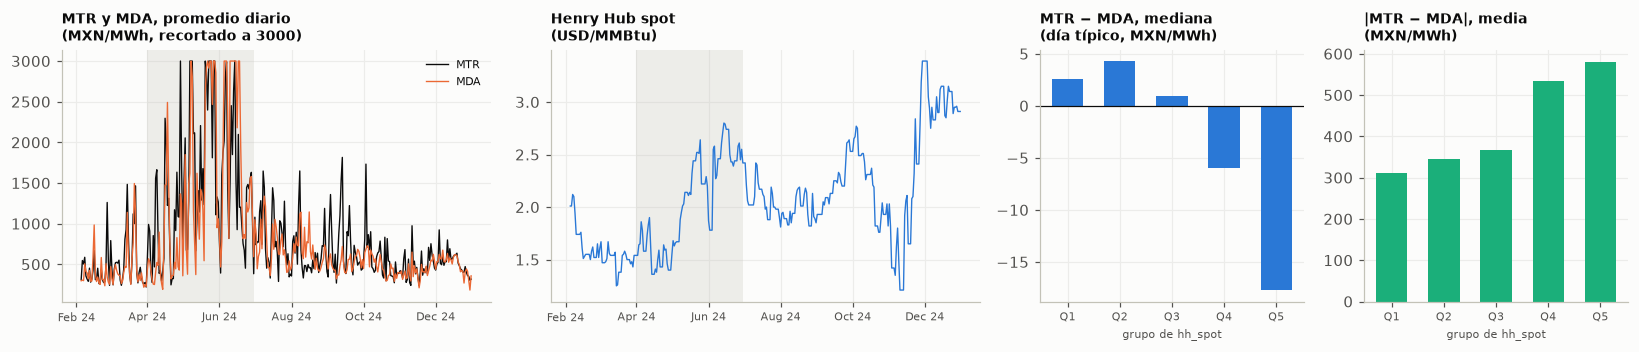

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,1.21 a 1.58,67,670.3,538.3,132.0,2.6,312.4,23.9
Q2,1.58 a 1.92,66,799.0,639.1,159.9,4.3,344.3,25.8
Q3,1.93 a 2.14,66,811.5,657.3,154.2,0.9,365.8,24.2
Q4,2.14 a 2.49,66,1054.2,1097.6,-43.4,-6.0,533.7,33.3
Q5,2.49 a 3.39,66,980.2,1290.0,-309.8,-17.7,581.0,18.2


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo            \
                         nivel MTR MTR − MDA |MTR − MDA|  nivel MTR MTR − MDA   
hh_spot                       0.50     -0.25        0.50       0.04     -0.06   
hh_spot_d7                    0.33      0.05        0.35      -0.05      0.00   
hh_spot_vol28                 0.12     -0.22        0.16      -0.14      0.03   
wti                          -0.03      0.26       -0.02       0.26     -0.07   
usdmxn                        0.06     -0.36        0.10      -0.32      0.04   
hh_mxn                        0.48     -0.27        0.48      -0.02     -0.04   

                           
              |MTR − MDA|  
hh_spot             -0.25  
hh_spot_d7          -0.10  
hh_spot_vol28       -0.31  
wti                  0.46  
usdmxn              -0.51  
hh_mxn              -0.33

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
hh_spot,-0.20,-0.21,-0.19,-0.21
hh_spot_d7,0.03,0.03,0.03,-0.03
hh_spot_vol28,-0.05,-0.02,-0.05,-0.01
wti,0.08,0.06,0.05,0.14
usdmxn,-0.12,-0.11,-0.10,-0.07
hh_mxn,-0.20,-0.21,-0.19,-0.20


In [3]:
# Combustibles y tipo de cambio (FRED): serie, promedios por quintil, correlaciones por periodo y por rezago
explorar(['hh_spot', 'hh_spot_d7', 'hh_spot_vol28', 'wti', 'usdmxn', 'hh_mxn'], 'hh_spot', 'Henry Hub spot', 'USD/MMBtu', '03_g6_combustibles.png')

Antes del desarrollo, Henry Hub acompaña al nivel del MTR (correlación 0.50) y a la magnitud del error (0.50). En el desarrollo esa relación desaparece (0.04) o cambia de signo (−0.25 con la magnitud). Con la diferencia MTR − MDA, que es lo que importa, la relación es débil y se mueve entre periodos (−0.25 y −0.06). El *cambio* semanal del gas no se relaciona con nada (0.05 y 0.00). El tipo de cambio muestra lo mismo: −0.36 con la diferencia antes del desarrollo y 0.04 después.

La tabla por quintiles lo aclara. La diferencia media pasa de +132 en el quintil más barato a −310 en el más caro, pero la **mediana** se queda entre −18 y +4 en todos. Lo que mueve la media son unos cuantos días de pico que coincidieron con cierto nivel del gas. El día típico no cambia con el precio del combustible.

Los combustibles se relacionan con el *nivel* del precio en la primavera de 2024, y esa relación es estacional (el gas y la ola de calor coincidieron), no causal en el día a día. El MDA ya incorpora el combustible. Que la correlación casi no cambie si el dato llega 1, 2 o 7 días más tarde (−0.20 a −0.21) confirma que no hay una señal oportuna que aprovechar. En el notebook 07, quitarle al modelo completo la familia de combustibles, gas y Texas sube algo el error de LEAR (+0.8%) y no el del gradient boosting (−0.4%): aportan poco, y solo a un modelo.

### 2.2 Inventarios de gas
Si el inventario está bajo frente a lo normal, el gas se vuelve escaso en las semanas siguientes. Es una variable lenta y semanal. Este es el ejemplo típico de fuga silenciosa: si se alinea por la fecha de la semana medida (viernes) en vez de por la fecha de publicación (jueves siguiente), el modelo "sabe" el dato seis días antes de que exista. Aquí se alinea por la publicación.

In [4]:
# Regla de publicación de los inventarios de gas: el dato de la semana que cierra el viernes se publica el jueves siguiente
pub = pd.Series(c.inv.values, index=c.inv.index + pd.Timedelta(days=6))
print('ejemplo: la semana que cierra el', c.inv.index[10].date(), 'se usa a partir del', (pub.index[10] + pd.Timedelta(days=c.lag_precios)).date())

ejemplo: la semana que cierra el 2024-01-12 se usa a partir del 2024-01-20


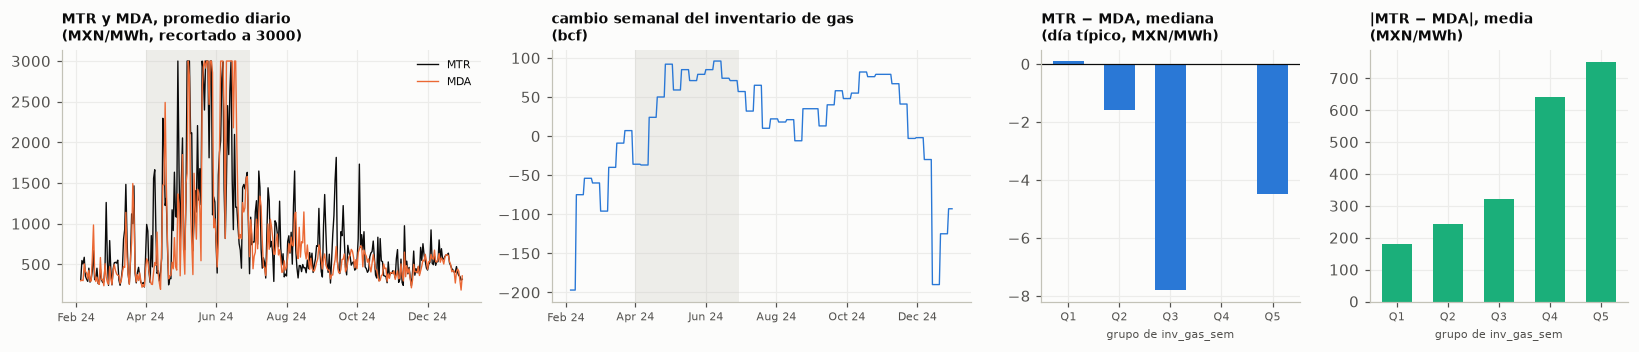

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,-197 a -36,67,511.2,414.4,96.8,0.1,181.8,7.5
Q2,-36 a 18,66,659.7,560.3,99.4,-1.6,243.6,18.2
Q3,18 a 50,66,721.0,670.0,50.9,-7.8,320.9,24.2
Q4,50 a 74,66,1199.4,1186.4,13.0,-0.0,640.7,34.8
Q5,74 a 96,66,1226.3,1392.9,-166.6,-4.5,752.2,40.9


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo            \
                        nivel MTR MTR − MDA |MTR − MDA|  nivel MTR MTR − MDA   
inv_gas                      0.36     -0.35        0.33      -0.35     -0.01   
inv_gas_sem                  0.65     -0.15        0.66      -0.07      0.07   
inv_gas_4sem                 0.65     -0.21        0.68      -0.03      0.10   

                          
             |MTR − MDA|  
inv_gas            -0.53  
inv_gas_sem         0.06  
inv_gas_4sem        0.06

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
inv_gas,-0.11,-0.11,-0.11,-0.12
inv_gas_sem,-0.05,-0.07,-0.08,-0.06
inv_gas_4sem,-0.10,-0.12,-0.13,-0.16


In [5]:
# Inventarios de gas (EIA)
explorar(['inv_gas', 'inv_gas_sem', 'inv_gas_4sem'], 'inv_gas_sem', 'cambio semanal del inventario de gas', 'bcf', '03_g6g_inventarios.png')

El patrón es el de una variable estacional. Antes del desarrollo, el cambio semanal del inventario se relaciona fuerte con el nivel del MTR (0.65) y con la magnitud del error (0.66). En el desarrollo, casi nada (−0.07 y 0.06). Con la diferencia es débil en los dos periodos (−0.15 y 0.07). Por quintiles, la media de la diferencia baja de +97 a −167, pero la mediana se queda entre −8 y 0.

Las inyecciones de gas al almacenamiento suben en primavera y verano, justo cuando hace calor y los precios suben, así que el inventario funciona como un reloj de la estación. No dice nada sobre si el MTR saldrá por encima o por debajo del MDA. Sin información útil, y además semanal: es la candidata más débil.

### 2.3 Demanda pronosticada de ERCOT
Texas está interconectado con el noreste de México y comparte el mercado de gas regional. Una demanda alta allá puede encarecer el gas y limitar los intercambios. Es la fuente con más riesgo de fuga, porque no se sabe con certeza a qué hora se fija el pronóstico `DF`. Si se actualizara durante el propio día, se estaría usando información posterior a la emisión. Se deja marcado y se trata como una candidata más, sin privilegios.

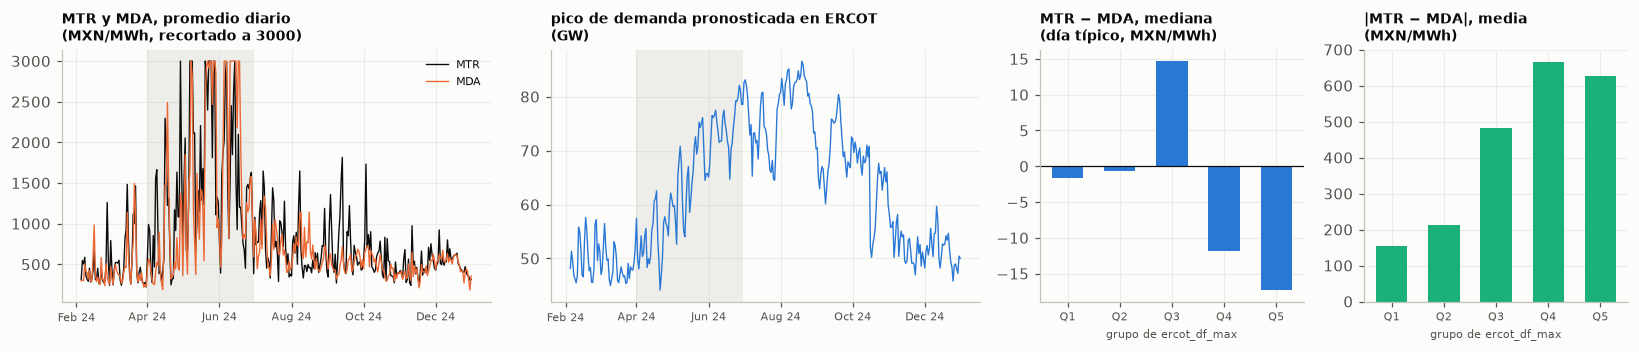

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,44.1 a 50.2,67,482.4,454.9,27.5,-1.6,152.9,6.0
Q2,50.2 a 55.8,66,586.9,447.9,139.1,-0.7,211.5,13.6
Q3,55.8 a 67,66,964.4,784.3,180.1,14.7,481.7,39.4
Q4,67.1 a 75.1,66,1196.2,1272.8,-76.7,-11.9,666.7,31.8
Q5,75.1 a 86.6,66,1088.1,1263.7,-175.6,-17.3,626.7,34.8


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo  \
                          nivel MTR MTR − MDA |MTR − MDA|  nivel MTR   
ercot_df_mean                  0.72     -0.14        0.69       0.34   
ercot_df_max                   0.71     -0.13        0.68       0.32   
ercot_df_eve                   0.70     -0.14        0.69       0.32   
ercot_df_rel28                 0.70      0.13        0.63       0.08   

                                      
               MTR − MDA |MTR − MDA|  
ercot_df_mean      -0.03        0.52  
ercot_df_max       -0.04        0.52  
ercot_df_eve       -0.02        0.53  
ercot_df_rel28     -0.14        0.06

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
ercot_df_mean,-0.13,-0.15,-0.22,-0.14
ercot_df_max,-0.11,-0.12,-0.18,-0.15
ercot_df_eve,-0.11,-0.12,-0.17,-0.14
ercot_df_rel28,-0.01,-0.06,-0.16,-0.09


In [6]:
# Pronóstico de demanda del día anterior de ERCOT (Texas)
explorar(['ercot_df_mean', 'ercot_df_max', 'ercot_df_eve', 'ercot_df_rel28'], 'ercot_df_max', 'pico de demanda pronosticada en ERCOT', 'GW', '03_g6e_ercot_df.png')

La demanda pronosticada de ERCOT es de las variables más relacionadas con el nivel del MTR (0.71 antes del desarrollo, 0.32 en el desarrollo) y con la magnitud del error (0.68 y 0.52). Con la diferencia, nada (−0.13 y −0.04). Por quintiles se repite el patrón de los combustibles: media de +180 en el quintil medio y −176 en el más alto, con medianas entre −17 y +15.

Cuando Texas pronostica mucha demanda hace calor en toda la región. El precio sube a ambos lados de la frontera y el MDA lo sabe. La señal sirve para anticipar **días nerviosos** (magnitud), no la dirección del error. Por eso podría tener algún valor en intervalos y no en el pronóstico puntual. En el notebook 07 entra en la familia de combustibles, gas y Texas, que aporta algo a LEAR (+0.8%) y nada al gradient boosting.

### 2.4 Clima de la zona de consumo
El clima de Monclova solo ayuda en la medida en que el calor del noreste acompaña al del resto del país. Para no meter 240 series horarias crudas se resume el día en variables con sentido físico:

- grados-hora de calor (sobre 24 y 28 °C) y de frío (bajo 15 °C);
- temperatura máxima, mínima, rango y hora del máximo;
- temperatura de la tarde y temperatura aparente;
- humedad, nubosidad y radiación, incluida la caída de radiación entre las 15–17 h y las 18–19 h, que es la rampa solar que estresa al sistema al anochecer;
- viento, lluvia y presión;
- anomalías contra los últimos 28 días.

Además van la temperatura y la radiación horarias. La serie es el promedio de dos puntos, las cabeceras de Monclova y de Frontera.

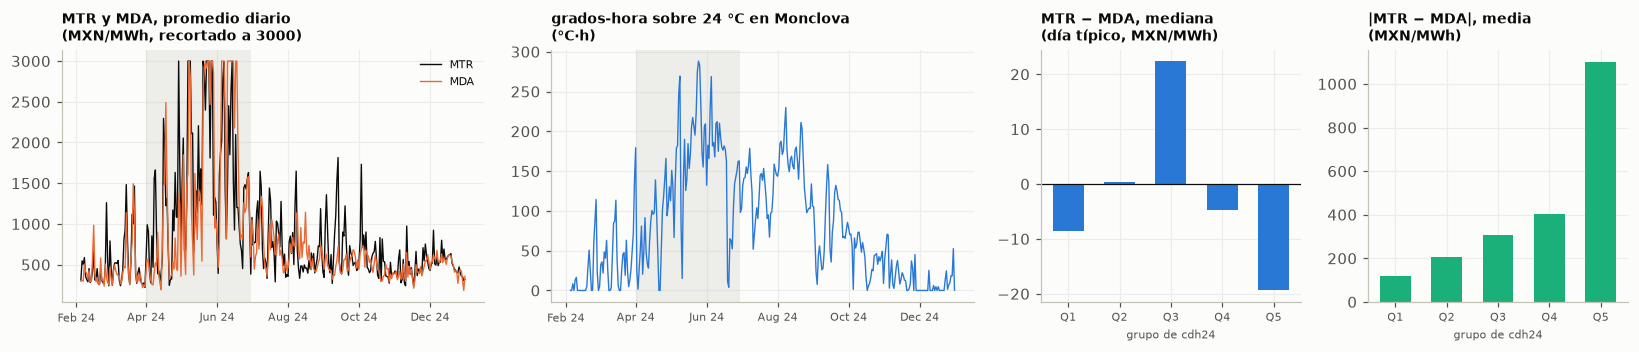

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,0 a 8.1,67,492.5,471.2,21.3,-8.6,119.3,4.5
Q2,8.4 a 45.3,66,537.0,457.6,79.4,0.3,205.2,10.6
Q3,46.3 a 96.7,66,707.4,536.6,170.9,22.4,309.1,22.7
Q4,97.7 a 153,66,928.8,779.5,149.4,-4.7,404.1,39.4
Q5,153 a 288,66,1652.1,1978.5,-326.4,-19.4,1102.4,48.5


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo  \
                           nivel MTR MTR − MDA |MTR − MDA|  nivel MTR   
cdh24                           0.74     -0.00        0.72       0.27   
tmax                            0.72      0.04        0.70       0.22   
tmax_anom28                     0.15      0.38        0.09      -0.02   
t_eve                           0.69     -0.01        0.68       0.28   
ghi_caida_tarde                 0.19      0.20        0.16      -0.01   
nub_tarde                      -0.21     -0.08       -0.21       0.22   
viento_eve                      0.40     -0.08        0.40       0.24   
presion                        -0.58     -0.24       -0.53      -0.08   

                                       
                MTR − MDA |MTR − MDA|  
cdh24               -0.04        0.54  
tmax                -0.05        0.49  
tmax_anom28         -0.05        0.09  
t_eve               -0.02        0.55  
ghi_caida_tarde     -0.12        0.19  
nub_tarde            0.07        0.13  
viento_eve          -0.08        0.44  
presion             -0.13       -0.27

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
cdh24,-0.01,-0.06,-0.10,-0.11
tmax,0.01,-0.05,-0.09,-0.07
tmax_anom28,0.20,0.08,0.03,0.06
t_eve,0.00,-0.03,-0.07,-0.08
ghi_caida_tarde,0.06,0.04,0.05,0.04
nub_tarde,-0.00,0.10,0.12,0.01
viento_eve,-0.08,-0.15,-0.17,-0.06
presion,-0.20,-0.09,0.04,-0.04


In [7]:
# Clima pronosticado para la zona de Monclova (calor, nubes, viento)
explorar(['cdh24', 'tmax', 'tmax_anom28', 't_eve', 'ghi_caida_tarde', 'nub_tarde', 'viento_eve', 'presion'], 'cdh24', 'grados-hora sobre 24 °C en Monclova', '°C·h', '03_g5_clima_zona.png')

Es el ejemplo más claro del patrón general:

- **Nivel y magnitud:** el calor en Monclova está muy relacionado con el nivel del MTR (0.74) y con la magnitud del error (0.72). La relación es más débil en el desarrollo (0.27 y 0.54), pero sigue ahí.
- **Diferencia:** casi cero en los dos periodos (0.00 y −0.04).
- **Quintiles:** la media de la diferencia es +171 en el quintil 3 y −326 en el más caluroso, donde el 48% de los días tuvo pico. La mediana va de −19 a +22. En el día típico el calor no inclina el error. En los días más calurosos de la primavera de 2024 el MDA *sobreestimó* en promedio, y en los días templados con pico lo *subestimó*.
- **Excepción:** la **anomalía de temperatura** (calor contra los últimos 28 días) sí se relaciona con la diferencia antes del desarrollo (0.38): un calor repentino tiende a salir más caro en tiempo real de lo que anticipó el MDA. En el desarrollo esa relación desaparece (−0.05). Es un efecto del arranque de la ola de calor de 2024, no algo que se repita.

El clima de la zona describe *qué tan grande* puede ser el error, pero no su dirección. La única señal de dirección dependió de un episodio. Esto cuadra con el notebook 07: quitarle el clima al modelo completo casi no cambia nada (LEAR +0.3%, gradient boosting −0.1%).

### 2.5 Clima de Monterrey y Texas
Monterrey es la carga más grande del Noreste. San Antonio representa la demanda de ERCOT y la cuenca de Eagle Ford, y Midland la Cuenca Pérmica, donde las heladas congelan pozos y cortan el gas que se exporta a México. Se esperaba que el calor de Monterrey se relacionara con el nivel del precio y, quizá, con días en que la demanda real supera a la prevista. De las heladas se esperaba poco en estos periodos, porque casi no hubo.

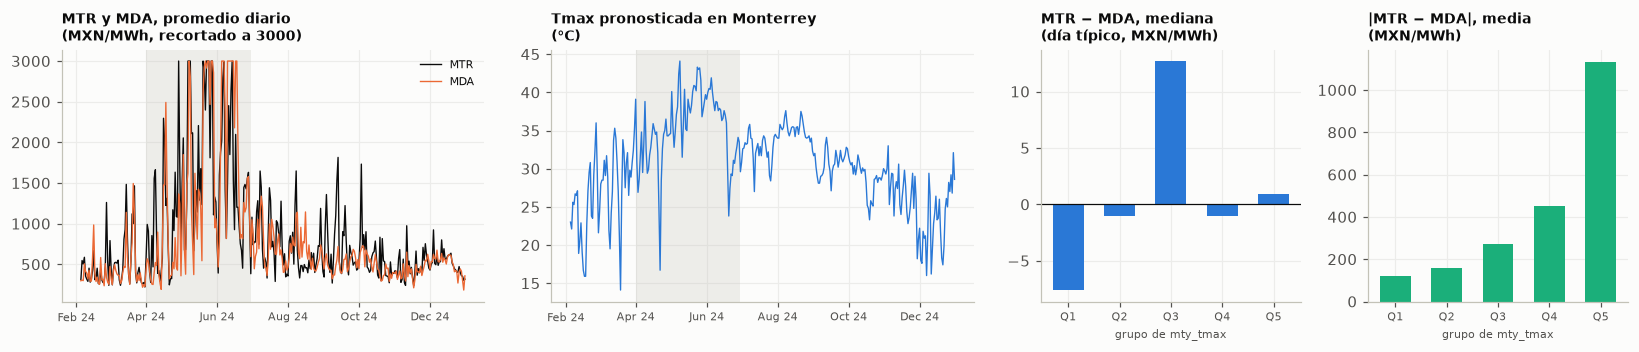

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,14.1 a 26.4,67,493.3,462.3,30.9,-7.6,122.7,4.5
Q2,26.5 a 29.5,66,486.4,436.6,49.8,-1.0,157.0,7.6
Q3,29.6 a 32.4,66,705.1,596.4,108.7,12.7,273.4,24.2
Q4,32.4 a 35.3,66,922.1,753.5,168.6,-1.0,452.6,34.8
Q5,35.3 a 44.1,66,1711.1,1974.6,-263.6,0.9,1134.3,54.5


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo  \
                           nivel MTR MTR − MDA |MTR − MDA|  nivel MTR   
mty_tmax                        0.76      0.08        0.75       0.24   
mty_cdh24                       0.79      0.08        0.77       0.27   
mty_tmax_anom28                 0.16      0.40        0.10      -0.04   
sa_cdh24                        0.69     -0.14        0.67       0.25   
tx_tmin                         0.68     -0.16        0.67       0.24   
tx_hdh0                        -0.10     -0.08       -0.08        NaN   

                                       
                MTR − MDA |MTR − MDA|  
mty_tmax            -0.05        0.53  
mty_cdh24           -0.05        0.55  
mty_tmax_anom28     -0.12        0.11  
sa_cdh24            -0.09        0.53  
tx_tmin             -0.06        0.50  
tx_hdh0               NaN         NaN

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
mty_tmax,0.04,-0.00,-0.07,-0.05
mty_cdh24,0.03,-0.01,-0.08,-0.06
mty_tmax_anom28,0.20,0.12,0.04,0.06
sa_cdh24,-0.13,-0.14,-0.15,-0.16
tx_tmin,-0.11,-0.11,-0.13,-0.17
tx_hdh0,-0.05,0.01,0.03,-0.04


In [8]:
# Clima de Monterrey (la carga grande del noreste) y de Texas (calor y heladas)
explorar(['mty_tmax', 'mty_cdh24', 'mty_tmax_anom28', 'sa_cdh24', 'tx_tmin', 'tx_hdh0'], 'mty_tmax', 'Tmax pronosticada en Monterrey', '°C', '03_g8_clima_noreste_texas.png')

Monterrey repite casi exactamente a Monclova:

- **Nivel y magnitud:** 0.76 y 0.75 antes del desarrollo; 0.24 y 0.53 en el desarrollo.
- **Diferencia:** casi cero (0.08 y −0.05). Por quintiles, la mediana de la diferencia se queda entre −8 y +13.
- **Anomalía de calor:** muestra lo mismo que en la zona, 0.40 antes del desarrollo y −0.12 después.
- **San Antonio y la mínima de Texas:** lo mismo.
- **Heladas:** el indicador de grados bajo cero de Texas no tiene variación en el desarrollo (sale vacío en la tabla), porque las heladas caen en el test.

El clima de Monterrey y Texas no agrega nada al de Monclova. El clima del noreste se mueve en bloque, y lo que dice ya está en el MDA. Las heladas son la excepción físicamente importante, pero con estos periodos no se pueden estudiar.

### 2.6 Estados operativos de CENACE
Una alerta (reserva operativa menor a 6%) o una emergencia (menor a 3%) indica que el sistema no tiene holgura. Se esperaba que unos días después de una alerta el MTR siguiera tenso, y que eso apareciera en la diferencia. Se usa el estado de *d−2* y el número de días con alerta en la semana previa.

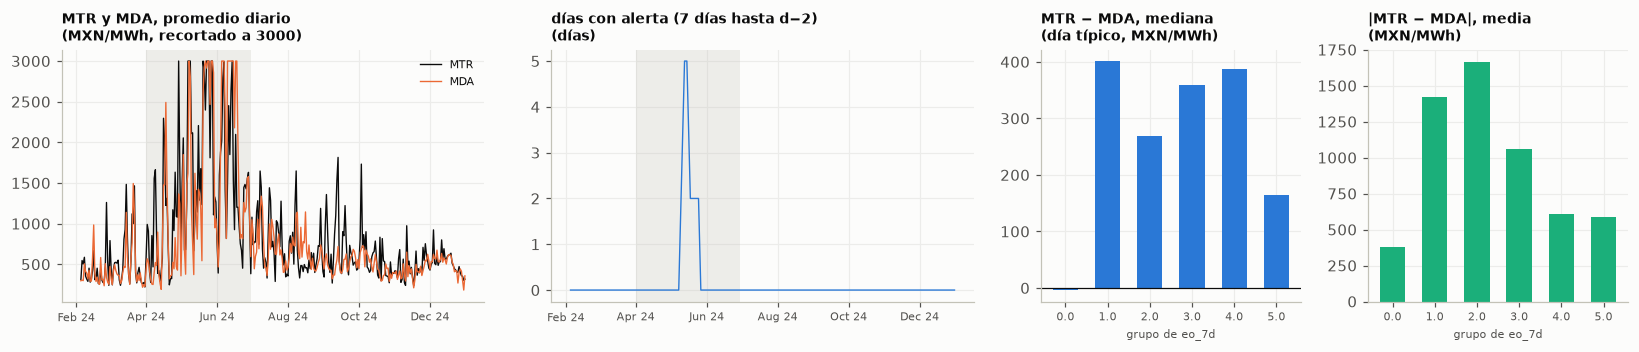

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
0.0,0 a 0,313,779.6,769.9,9.7,-3.7,378.3,22.0
1.0,1 a 1,2,3237.7,2636.0,601.8,401.4,1423.2,100.0
2.0,2 a 2,9,2788.1,2824.0,-35.9,268.6,1667.2,100.0
3.0,3 a 3,2,1703.0,1068.7,634.3,358.5,1059.3,100.0
4.0,4 a 4,2,1436.0,898.4,537.6,386.9,606.3,50.0
5.0,5 a 5,3,1204.6,1198.7,5.9,165.3,589.1,0.0


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo            \
                 nivel MTR MTR − MDA |MTR − MDA|  nivel MTR MTR − MDA   
eo_d2                 0.20      0.26        0.19        NaN       NaN   
eo_7d                 0.38      0.18        0.31        NaN       NaN   

                   
      |MTR − MDA|  
eo_d2         NaN  
eo_7d         NaN

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
eo_d2,0.18,0.15,0.10,0.08
eo_7d,0.13,0.11,0.07,-0.01


In [9]:
# Alertas y emergencias del sistema publicadas por CENACE (sólo se usan hasta d−2)
explorar(['eo_d2', 'eo_7d'], 'eo_7d', 'días con alerta (7 días hasta d−2)', 'días', '03_g8_estados_operativos.png')

De 331 días hasta diciembre de 2024, solo 18 tienen alguna alerta en la ventana de 7 días, todos de mayo de 2024. En el desarrollo la variable vale cero siempre, por eso esa parte de la tabla sale vacía. Lo que se ve es notable. Después de una alerta, la **mediana** de la diferencia es positiva y grande, entre +165 y +401 MXN/MWh según el número de días con alerta, contra −4 en los días sin alerta. En 14 de esos 18 días hubo pico. La correlación con la diferencia antes del desarrollo es 0.26 para el estado de *d−2* y baja si el dato llega más tarde (0.18 → 0.08 a 7 días).

Es la única variable con una relación clara con la **dirección** del error: tras una alerta, el MTR sale sistemáticamente por encima del MDA. El sistema sigue tenso y el MDA no lo anticipa del todo. El problema es que todo descansa en un episodio de dos semanas. No hay forma de saber si se repetiría, ni de evaluarlo en desarrollo, ni de que un modelo lo aprenda sin sobreajustar. Se queda documentada como la señal de mayor potencial que la escasez de datos impide aprovechar.

### 2.7 Vacaciones
Con escuelas cerradas, Semana Santa o fin de año baja la demanda comercial y residencial, y en parte la industrial. El MDA ya conoce el calendario, así que se esperaba que el nivel bajara en vacaciones pero que la diferencia no cambiara mucho, salvo quizá en días donde el MDA sobreestima la demanda.

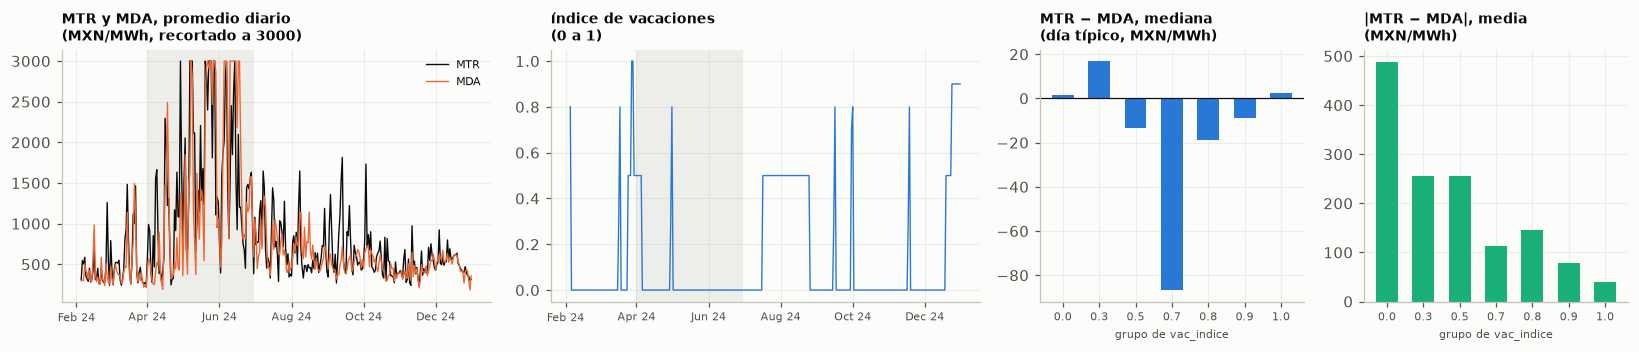

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
0.0,0 a 0,255,950.4,931.2,19.2,1.6,488.7,28.6
0.3,0.3 a 0.3,4,678.3,560.6,117.7,16.9,255.8,25.0
0.5,0.5 a 0.5,55,613.8,611.1,2.7,-13.2,255.3,14.5
0.7,0.7 a 0.7,1,444.1,557.8,-113.6,-86.7,113.6,0.0
0.8,0.8 a 0.8,6,443.6,342.0,101.6,-18.9,145.6,16.7
0.9,0.9 a 0.9,8,376.1,346.8,29.3,-9.0,77.5,0.0
1.0,1 a 1,2,267.2,254.5,12.7,2.4,39.8,0.0


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo            \
                      nivel MTR MTR − MDA |MTR − MDA|  nivel MTR MTR − MDA   
vac_sep                   -0.28      0.05       -0.29      -0.06     -0.23   
vac_indice                -0.31      0.06       -0.31      -0.15     -0.21   
vac_finde                 -0.20     -0.03       -0.19      -0.19     -0.18   

                        
           |MTR − MDA|  
vac_sep           0.12  
vac_indice        0.03  
vac_finde        -0.05

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
vac_sep,-0.13,-0.12,-0.10,-0.06
vac_indice,-0.11,-0.08,-0.05,-0.04
vac_finde,-0.13,-0.05,-0.02,-0.09


In [10]:
# Índice de vacaciones (calendario SEP)
explorar(['vac_sep', 'vac_indice', 'vac_finde'], 'vac_indice', 'índice de vacaciones', '0 a 1', '03_g7v_vacaciones.png')

Resultados:
- **Nivel:** las vacaciones bajan el nivel del MTR (−0.31 antes del desarrollo, −0.15 en el desarrollo), como se esperaba.
- **Diferencia:** la relación cambia entre periodos, 0.06 antes del desarrollo y −0.21 en el desarrollo. Ese −0.21 dice que en las vacaciones de la segunda mitad de 2024 (verano y fin de año) el MTR tendió a quedar **por debajo** del MDA: el MDA sobreestimó la demanda de esos días.
- **Por grupos:** las medianas de la diferencia son pequeñas (−13 en los 55 días de vacaciones escolares y entre −19 y +17 en los grupos con más de un día).
- **Magnitud:** el error es mucho menor en vacaciones (255 contra 489 en días normales). Son días tranquilos.

Hay una señal de dirección modesta en el desarrollo, consistente con la idea de que el MDA no termina de ajustar la caída de demanda en vacaciones. Es pequeña frente al ruido: en el notebook 07, quitarle el calendario y las vacaciones al modelo completo sube el error del gradient boosting 0.9% y no el de LEAR (−0.4%). Probablemente ya la captura en parte el día de la semana, porque buena parte del efecto ocurre en fines de semana.

### 2.8 Operación real de ERCOT, EIA-930
Esta fuente es nueva. EIA publica cada hora lo que *pasó* en ERCOT: demanda real, generación por combustible y el intercambio con CENACE. Se da por conocido el día *d−2* completo. Es lo más cercano que se tiene a "lo que ocurrió en tiempo real ayer" en la región vecina. Se esperaban tres mecanismos:

- **una sorpresa de demanda** en Texas (real contra pronóstico del día anterior) podría acompañar sorpresas del lado mexicano por el mismo clima;
- **poca generación eólica** en Texas obliga a quemar más gas y puede tensar el gas regional;
- **las exportaciones de ERCOT a México** suben cuando el norte de México necesita energía, una señal directa de estrés en el Noreste.

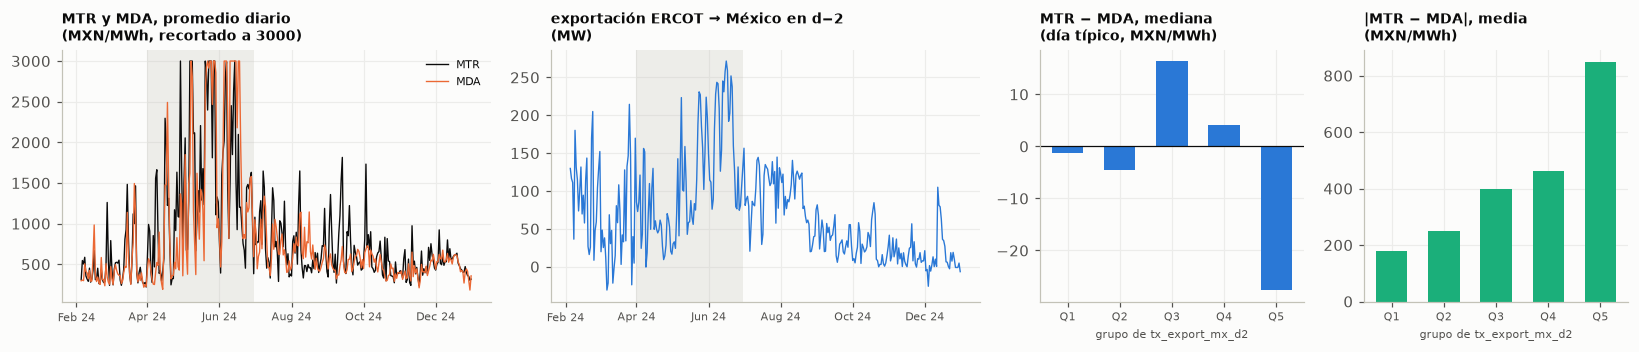

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,-30.8 a 14.7,67,555.5,446.8,108.7,-1.3,180.5,13.4
Q2,15 a 39.8,66,670.7,559.7,110.9,-4.6,248.0,24.2
Q3,40.4 a 74.8,66,888.2,680.8,207.4,16.4,398.7,30.3
Q4,75.2 a 122,66,962.6,893.4,69.1,4.1,462.1,25.8
Q5,123 a 272,66,1240.1,1643.0,-402.9,-27.6,849.9,31.8


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo  \
                                nivel MTR MTR − MDA |MTR − MDA|  nivel MTR   
tx_dem_sorpresa_d2                   0.23     -0.01        0.23      -0.01   
tx_dem_max_d2                        0.64     -0.23        0.65       0.28   
tx_eolica_anom_d2                   -0.04     -0.03       -0.02      -0.11   
tx_gas_share_d2                      0.27     -0.11        0.24       0.19   
tx_export_mx_d2                      0.23     -0.35        0.29       0.20   
tx_export_mx_eve_d2                  0.17     -0.35        0.24       0.11   
tx_export_mx_anom_d2                 0.15     -0.14        0.19      -0.23   

                                            
                     MTR − MDA |MTR − MDA|  
tx_dem_sorpresa_d2        0.04        0.04  
tx_dem_max_d2            -0.07        0.47  
tx_eolica_anom_d2         0.05       -0.06  
tx_gas_share_d2          -0.09        0.31  
tx_export_mx_d2          -0.10        0.37  
tx_export_mx_eve_d2      -0.10        0.28  
tx_export_mx_anom_d2     -0.24       -0.21

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
tx_dem_sorpresa_d2,0.02,-0.05,-0.03,0.03
tx_dem_max_d2,-0.17,-0.23,-0.23,-0.12
tx_eolica_anom_d2,0.01,-0.03,-0.05,-0.02
tx_gas_share_d2,-0.11,-0.11,-0.07,-0.05
tx_export_mx_d2,-0.19,-0.18,-0.13,-0.15
tx_export_mx_eve_d2,-0.22,-0.19,-0.13,-0.13
tx_export_mx_anom_d2,-0.17,-0.17,-0.09,-0.12


In [11]:
# Operación real de ERCOT publicada (d−2): demanda, eólica, gas y exportación hacia México
explorar(['tx_dem_sorpresa_d2', 'tx_dem_max_d2', 'tx_eolica_anom_d2', 'tx_gas_share_d2', 'tx_export_mx_d2', 'tx_export_mx_eve_d2', 'tx_export_mx_anom_d2'], 'tx_export_mx_d2', 'exportación ERCOT → México en d−2', 'MW', '03_g9_ercot_operacion.png')

Se ve lo siguiente:
- **Demanda e intercambio, nivel y magnitud:** la demanda real de ERCOT y la exportación de ERCOT hacia México se relacionan con el nivel y la magnitud como el calor (0.64 y 0.65 la demanda máxima antes del desarrollo).
- **Exportación hacia México y diferencia:** −0.35 antes del desarrollo y −0.10 en el desarrollo. La **anomalía** de la exportación (contra su promedio de 28 días) tiene signo negativo en los dos periodos (−0.14 y −0.24), y es la más estable de esta fuente.
- **Quintiles:** cuando ERCOT exportó mucho a México, la mediana de la diferencia fue −28, contra valores entre −5 y +16 en los demás quintiles.
- **Sorpresa de demanda de Texas y viento de Texas:** no se relacionan con la diferencia (correlación de ± 0.05).

Las exportaciones de Texas a México suben cuando el norte de México necesita energía. En esos días el MDA ya pone un precio alto y el tiempo real suele salir algo más barato, como si el MDA sobrerreaccionara al estrés que ve venir. La señal es débil pero tiene el mismo signo en los dos periodos, lo que no pasa con casi ninguna otra exógena. Pierde fuerza si el dato llega más tarde (−0.17 → −0.09 a 2 días), así que tener *d−2* importa. La sorpresa de demanda de Texas no transmite nada: lo que pasa en el tiempo real de Texas no anticipa el tiempo real de México.

### 2.9 Precio en tiempo real de ERCOT
Otra fuente nueva: el precio de tiempo real de ERCOT, publicado cada 15 minutos (reporte público NP6-785). Se usa el día *d−2* completo y la mañana de *d−1* hasta las 11:00. Es el equivalente texano del MTR, pero conocido casi al instante. Si las sorpresas de tiempo real en Texas y en México tuvieran causas comunes (calor regional, gas de Texas), el precio RT de ERCOT reciente sería la mejor ventana a ese estrés. Los precios se pasan a asinh(precio/50), porque tienen picos de hasta 5000 USD/MWh.

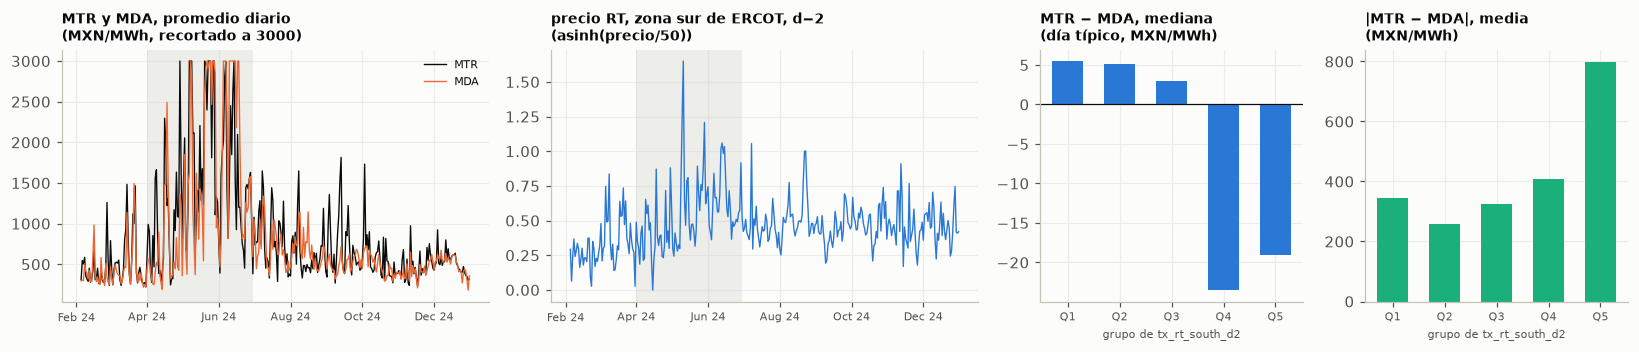

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,-0.00087 a 0.318,67,792.9,616.0,177.0,5.5,345.3,23.9
Q2,0.32 a 0.413,66,681.2,542.0,139.3,5.1,257.2,21.2
Q3,0.413 a 0.479,66,799.3,693.6,105.7,3.0,326.0,21.2
Q4,0.479 a 0.597,66,780.5,898.6,-118.0,-23.5,408.5,24.2
Q5,0.6 a 1.65,66,1259.3,1471.0,-211.7,-19.0,799.6,34.8


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo  \
                               nivel MTR MTR − MDA |MTR − MDA|  nivel MTR   
tx_rt_hub_d2                        0.30     -0.17        0.30      -0.04   
tx_rt_hub_max_d2                    0.16     -0.01        0.15      -0.08   
tx_rt_west_d2                       0.14     -0.09        0.10       0.00   
tx_rt_south_d2                      0.46     -0.25        0.48      -0.07   
tx_rt_hub_manana_d1                 0.19     -0.15        0.18       0.05   

                                           
                    MTR − MDA |MTR − MDA|  
tx_rt_hub_d2            -0.22       -0.02  
tx_rt_hub_max_d2        -0.16        0.02  
tx_rt_west_d2           -0.18       -0.00  
tx_rt_south_d2          -0.25       -0.01  
tx_rt_hub_manana_d1     -0.12       -0.13

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
tx_rt_hub_d2,-0.19,-0.20,-0.15,-0.02
tx_rt_hub_max_d2,-0.08,-0.07,-0.05,0.03
tx_rt_west_d2,-0.13,-0.14,-0.09,-0.02
tx_rt_south_d2,-0.25,-0.26,-0.23,-0.07
tx_rt_hub_manana_d1,-0.13,-0.17,-0.11,0.02


In [12]:
# Precio en tiempo real de ERCOT (hasta d−1 a las 11:00)
explorar(['tx_rt_hub_d2', 'tx_rt_hub_max_d2', 'tx_rt_west_d2', 'tx_rt_south_d2', 'tx_rt_hub_manana_d1'], 'tx_rt_south_d2', 'precio RT, zona sur de ERCOT, d−2', 'asinh(precio/50)', '03_g9_ercot_rt.png')

Es la fuente nueva más interesante:

- **Estabilidad:** el precio RT de la zona sur de ERCOT tiene una relación con la diferencia **igual en los dos periodos** (−0.25 y −0.25). Con el hub promedio pasa algo parecido (−0.17 y −0.22).
- **Quintiles:** la mediana de la diferencia es +3 a +6 en los tres quintiles más baratos y −19 a −24 en los dos más caros, un cambio de dirección del error del día típico, no solo de su tamaño.
- **Desacople del nivel:** la relación con el nivel del MTR desaparece en el desarrollo (−0.07), así que no es un simple reflejo del precio.
- **Rezago:** la señal se mantiene si el dato llega 1 o 2 días más tarde (−0.26 y −0.23) y se pierde a los 7 días (−0.07). Es información reciente con vida corta.

Cuando el tiempo real de Texas estuvo caro dos días antes, el MTR de Monclova tiende a quedar *por debajo* del MDA. Una lectura posible: el MDA incorpora el estrés regional reciente y lo extrapola, y el tiempo real corrige hacia abajo. Es una relación pequeña (correlación de 0.25) pero estable y con mecanismo plausible, la mejor candidata nueva para los modelos del notebook 07.

### 2.10 Clima de los grandes centros de carga y zonas renovables
La energía es un precio nacional, así que el clima que importa es el de donde está la carga (CDMX, Guadalajara, Monterrey) y donde está la generación renovable (sol de Sonora, viento del Istmo de Tehuantepec y de Tamaulipas). Además del pronóstico emitido con 48 h de anticipación, se mide su **revisión**: la diferencia contra el pronóstico de 72 h. La idea es que una revisión grande es información nueva que el MDA quizá no alcanzó a incorporar. Una salvedad: las dos corridas son anteriores al cierre del MDA, así que el MDA pudo haber visto ambas.

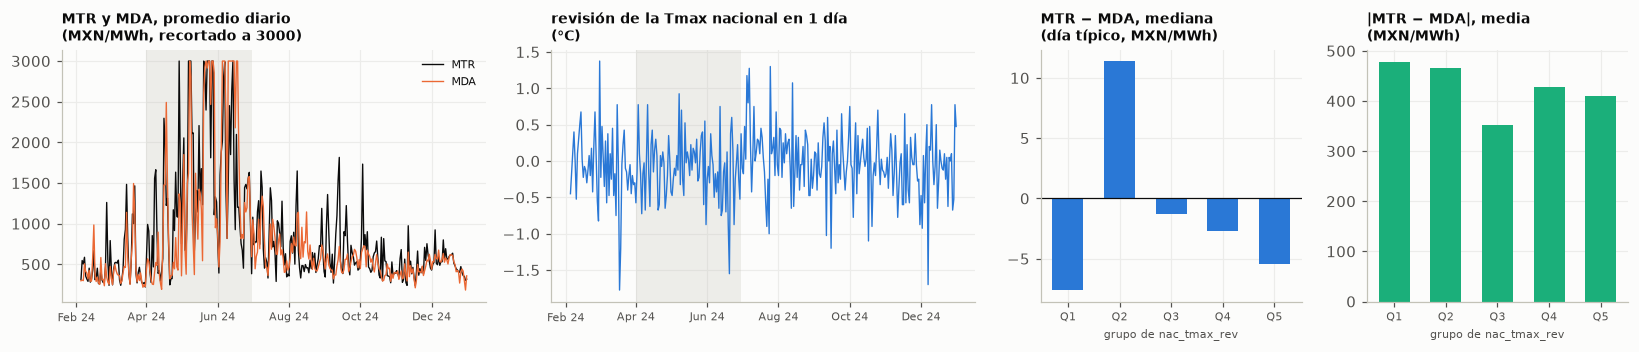

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,-1.77 a -0.4,67,853.6,947.7,-94.1,-7.6,478.5,26.9
Q2,-0.4 a -0.15,66,875.4,873.7,1.8,11.4,466.7,21.2
Q3,-0.15 a 0.05,66,802.6,694.6,108.0,-1.3,352.6,24.2
Q4,0.05 a 0.3,66,903.4,887.6,15.8,-2.7,427.8,33.3
Q5,0.3 a 1.38,66,877.3,812.5,64.8,-5.4,409.0,19.7


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo  \
                           nivel MTR MTR − MDA |MTR − MDA|  nivel MTR   
nac_tmax                        0.76     -0.08        0.77       0.34   
nac_tmax_rev                    0.04      0.03        0.02       0.06   
cdmx_cdh24                      0.48      0.27        0.45       0.27   
gdl_cdh24                       0.60      0.07        0.63       0.13   
hmo_ghi_tarde                   0.65     -0.13        0.69       0.32   
hmo_ghi_rev                     0.01     -0.08       -0.00      -0.11   
juch_viento                    -0.40      0.04       -0.37      -0.24   
juch_viento_eve                -0.38      0.06       -0.36      -0.22   
juch_viento_rev                 0.15     -0.02        0.13       0.19   
rey_viento_eve                  0.27      0.01        0.31       0.07   

                                       
                MTR − MDA |MTR − MDA|  
nac_tmax            -0.00        0.58  
nac_tmax_rev         0.03        0.09  
cdmx_cdh24           0.20        0.39  
gdl_cdh24            0.07        0.18  
hmo_ghi_tarde       -0.02        0.54  
hmo_ghi_rev         -0.15       -0.01  
juch_viento         -0.16       -0.36  
juch_viento_eve     -0.19       -0.32  
juch_viento_rev      0.07        0.17  
rey_viento_eve      -0.03        0.25

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
nac_tmax,-0.03,-0.08,-0.12,-0.07
nac_tmax_rev,0.02,0.02,-0.00,-0.09
cdmx_cdh24,0.18,0.12,0.05,0.07
gdl_cdh24,0.08,0.06,-0.00,0.01
hmo_ghi_tarde,-0.05,-0.06,-0.11,-0.04
hmo_ghi_rev,-0.12,0.03,-0.15,0.08
juch_viento,-0.11,-0.02,0.04,-0.05
juch_viento_eve,-0.11,-0.01,0.01,-0.04
juch_viento_rev,0.03,-0.09,-0.12,-0.07
rey_viento_eve,-0.01,-0.02,-0.09,-0.15


promedios por grupo de los grados-hora de calor en CDMX:


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,0 a 0,67,571.2,529.9,41.3,-11.0,186.9,7.5
Q2,0 a 2.5,66,559.2,567.5,-8.3,-13.6,170.4,13.6
Q3,2.5 a 8.7,66,718.9,613.2,105.7,4.1,293.3,24.2
Q4,8.9 a 27,66,820.2,909.9,-89.7,3.3,501.4,27.3
Q5,27.1 a 61.8,66,1647.2,1601.9,45.3,94.6,987.0,53.0


In [13]:
# Clima de los grandes centros de carga y de las zonas renovables del país, y sus revisiones de pronóstico
explorar(['nac_tmax', 'nac_tmax_rev', 'cdmx_cdh24', 'gdl_cdh24', 'hmo_ghi_tarde', 'hmo_ghi_rev', 'juch_viento', 'juch_viento_eve', 'juch_viento_rev', 'rey_viento_eve'], 'nac_tmax_rev', 'revisión de la Tmax nacional en 1 día', '°C', '03_g9_clima_nacional.png')
print('promedios por grupo de los grados-hora de calor en CDMX:'); display(ex.quintiles(FX, O, 'cdmx_cdh24'))

Resultados:
- **Calor en los centros de carga:** acompaña al nivel del MTR (0.76 la Tmax nacional antes del desarrollo) y a la magnitud (0.77 y 0.58), igual que el clima de la zona.
- **Revisiones del pronóstico:** prácticamente nada (0.03 y 0.03 para la Tmax nacional; −0.08 y −0.15 para la radiación de Sonora). Por quintiles, la mediana de la diferencia no tiene orden (−8 a +11).
- **Calor en CDMX:** es la excepción. Sus grados-hora de calor se relacionan con la diferencia en los dos periodos (0.27 y 0.20), y en el quintil más caluroso la mediana de la diferencia es **+95 MXN/MWh**, contra −14 a +4 en los demás. Cuando hace mucho calor en el centro del país, el tiempo real sale más caro de lo que anticipó el MDA en un día típico.
- **Viento del Istmo:** no es estable (0.04 y −0.16).

Que una revisión del pronóstico no diga nada confirma que el MDA ya vio esas corridas. Las dos se emitieron antes de su cierre, así que no hay "información nueva" en el clima a la hora en que se pronostica. El calor de la Ciudad de México sí parece llevar una señal de dirección estable. Una hipótesis: es el centro de carga más grande y lejano a la generación del norte, y su calor extremo tensa la transmisión en tiempo real más de lo que el MDA prevé. Va a los modelos del notebook 07 junto con el precio RT de ERCOT.

### 2.11 ¿Qué parte del error es local? Los componentes del PML

Hasta aquí el PML se trata como un solo número. CENACE lo publica separado en tres componentes: **energía** (el costo de la última planta que se necesita en todo el sistema), **pérdidas** y **congestión** (lo que cuesta llevar la energía a ese nodo cuando las líneas se saturan). La energía es, por construcción, un precio del sistema. Si eso se cumple en los datos, cambia qué información vale la pena buscar: para la energía importa lo que pasa en todo el país; lo local solo puede explicar la congestión y las pérdidas.

Para comprobarlo se descargaron el MDA y el MTR de 31 nodos de la red elegidos con el catálogo oficial de NodosP de CENACE: el corredor del carbón (Río Escondido, Carbón II, Nava), Saltillo, Monterrey, Tamaulipas, la Laguna y Chihuahua, el Valle de México y Tula, Guadalajara y el Bajío, Manzanillo, el sureste (Laguna Verde, Chicoasén, Tuxpan, Juchitán, Puebla), Sonora y Mérida (`src/pml/red.py`). Abajo, el error del MDA de Monclova separado por componente, de febrero a diciembre de 2024.

In [14]:
# ¿En qué componente está el error del MDA? Error absoluto, sesgo y relación con el error total de energía, pérdidas y
# congestión. Después se comprueba con los nodos de la red que la energía es idéntica en todo el SIN
per = slice(f2.TRAIN_START, f2.DEV_FIN)
D = {k: (c.comp['MTR'][k] - c.comp['MDA'][k]).loc[per] for k in ('ene', 'per', 'cng')}
tot = (c.Y - c.X).loc[per]
T = pd.DataFrame({n: {'error absoluto medio (MXN/MWh)': D[k].abs().values.mean(), 'sesgo medio MTR − MDA (MXN/MWh)': D[k].values.mean(),
                      'correlación con el error total': np.corrcoef(D[k].values.ravel(), tot.values.ravel())[0, 1]}
                  for k, n in (('ene', 'energía'), ('per', 'pérdidas'), ('cng', 'congestión'))}).T.round(2)
display(T); print('error absoluto medio del PML total:', round(np.abs(tot.values).mean(), 1))
from pml import red
r = red.cargar('MTR'); mon = pd.read_parquet(ROOT / 'data/processed/pml_mtr.parquet')
e = r.merge(mon[mon.nodo == '06MON-115'][['fecha', 'hora', 'pml_ene']], on=['fecha', 'hora'], suffixes=('', '_mon'))
print('diferencia máxima de la componente de energía entre los 31 nodos de la red y Monclova:', (e.pml_ene - e.pml_ene_mon).abs().max(), 'MXN/MWh')
H = pd.DataFrame({'congestión MDA': c.comp['MDA']['cng'].loc[per].median(), 'congestión MTR': c.comp['MTR']['cng'].loc[per].median()}).T.round(1)
print('mediana por hora de la congestión en Monclova (MXN/MWh):'); display(H[[1, 6, 12, 15, 17, 18, 19, 20, 22, 24]])

,error absoluto medio (MXN/MWh),sesgo medio MTR − MDA (MXN/MWh),correlación con el error total
energía,444.53,-0.91,0.98
pérdidas,25.11,-1.58,-0.26
congestión,82.42,21.41,0.12


error absoluto medio del PML total: 427.1


diferencia máxima de la componente de energía entre los 31 nodos de la red y Monclova: 0.0 MXN/MWh
mediana por hora de la congestión en Monclova (MXN/MWh):


hora,1,6,12,15,17,18,19,20,22,24
congestión MDA,-6.4,-8.7,-2.4,-12.5,-15.8,-24.8,-17.7,-6.9,-8.2,-11.6
congestión MTR,-7.3,-6.7,-4.1,-7.7,-10.4,-11.4,-8.6,-1.2,-5.7,-6.4


Se ve lo siguiente:
- **La energía es la misma en todo el sistema.** En todas las horas desde diciembre de 2023, la componente de energía de los 31 nodos de la red es idéntica a la de Monclova (diferencia máxima: 0.0 MXN/MWh).
- **El error es casi todo energía.** De febrero a diciembre de 2024, el error absoluto medio de la energía es 445 MXN/MWh y su correlación con el error total es 0.98. La congestión aporta 82 y las pérdidas 25; sus correlaciones con el error total son 0.12 y −0.26. Los componentes se compensan en parte, por eso la suma de sus errores pasa del error total (427).
- **El MDA exagera la congestión de Monclova.** El sesgo de la congestión es +21 MXN/MWh: la congestión es negativa (Monclova es una zona que exporta energía hacia otras regiones) y el MTR resulta menos negativo que el MDA. El efecto es más marcado entre las 17 y las 19 h: a las 18 h, la mediana del MDA es −24.8 y la del MTR −11.4.

Esto ordena la búsqueda de información. Todo lo que mueve el error grande (la energía) es nacional: la demanda de todo el país, la generación disponible, el gas. Ahí no ayuda mirar más nodos, porque todos tienen la misma energía. Ahí ayuda el clima nacional (sección 2.13) y lo que dice la red sobre el estado del sistema. La congestión es la parte chica pero sistemática: el MTR encoge la congestión que trae el MDA, y eso se puede corregir con la congestión del propio MDA (sección 2.12). También sugiere modelar las dos partes por separado (idea descartada, ver el README). Y explica el calor de la Ciudad de México (sección 2.10): afecta a Monclova a través del precio nacional de la energía, no por la red local.

### 2.12 Congestión del MDA en Monclova y en la red
Si el error local es la congestión, la información para pronosticarlo está en la congestión que el MDA de *d* ya publicó: la de Monclova (¿la exagera y el MTR la encoge?) y la de los corredores de la red, que dice hacia dónde fluye la potencia. El MDA de *d* se conoce al emitir, así que es legítimo. Del MTR de la red se usa solo el error reciente de congestión, hasta *d−8*. Los 31 nodos se resumen por corredor, porque con 17 meses no se le pueden dar al modelo 31 × 24 columnas.

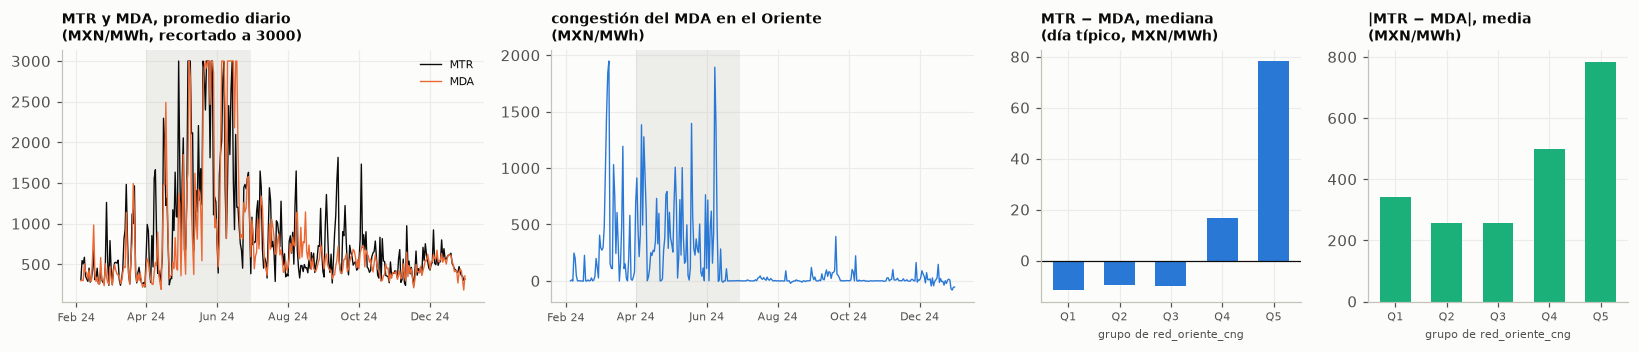

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,-81.6 a -0.25,67,690.5,810.2,-119.7,-11.6,340.2,9.0
Q2,-0.237 a 1.53,66,632.2,628.1,4.1,-9.6,257.0,12.1
Q3,1.58 a 26.1,66,652.6,589.5,63.2,-10.2,257.1,24.2
Q4,26.3 a 243,66,1003.9,947.6,56.3,16.6,497.7,31.8
Q5,246 a 1.95e+03,66,1335.7,1242.9,92.8,78.3,784.7,48.5


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo  \
                                 nivel MTR MTR − MDA |MTR − MDA|  nivel MTR   
cngmda_dia                            0.19     -0.24        0.14       0.20   
cngmda_eve                            0.23     -0.27        0.18       0.30   
cng_err7_d8                          -0.14      0.25       -0.13      -0.02   
red_carbon_cng_eve                    0.20     -0.27        0.16       0.30   
red_monterrey_cng_eve                 0.27     -0.27        0.21       0.30   
red_centro_cng                       -0.25      0.16       -0.24       0.14   
red_occidente_cng                     0.25      0.03        0.26       0.16   
red_oriente_cng                       0.21      0.35        0.21       0.20   
red_peninsular_cng                    0.17      0.35        0.14       0.17   
red_noroeste_cng                     -0.78      0.04       -0.77       0.08   
red_grad_norte_centro                 0.27     -0.26        0.21       0.15   

                                             
                      MTR − MDA |MTR − MDA|  
cngmda_dia                 0.06        0.07  
cngmda_eve                 0.01        0.21  
cng_err7_d8               -0.06       -0.08  
red_carbon_cng_eve         0.01        0.22  
red_monterrey_cng_eve      0.01        0.20  
red_centro_cng             0.11        0.03  
red_occidente_cng         -0.02        0.03  
red_oriente_cng            0.18        0.11  
red_peninsular_cng         0.13        0.11  
red_noroeste_cng           0.03       -0.10  
red_grad_norte_centro     -0.01        0.03

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
cngmda_dia,-0.08,-0.02,-0.04,-0.02
cngmda_eve,-0.12,-0.13,-0.18,-0.05
cng_err7_d8,0.14,0.12,0.08,0.13
red_carbon_cng_eve,-0.12,-0.13,-0.18,-0.05
red_monterrey_cng_eve,-0.12,-0.11,-0.17,-0.02
red_centro_cng,0.14,0.17,0.09,0.16
red_occidente_cng,-0.00,-0.04,-0.10,-0.02
red_oriente_cng,0.26,0.19,0.15,0.10
red_peninsular_cng,0.25,0.24,0.19,0.06
red_noroeste_cng,-0.02,0.03,0.03,0.01


promedios por grupo de red_peninsular_cng:


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,-904 a -0.0146,67,699.2,850.9,-151.7,-11.6,375.5,9.0
Q2,0.0229 a 8.61,66,638.1,661.8,-23.7,-9.0,260.2,13.6
Q3,8.77 a 66.7,66,632.2,565.8,66.4,-6.3,234.8,19.7
Q4,71.5 a 406,66,1155.4,1101.4,54.0,5.8,620.2,39.4
Q5,408 a 4.36e+03,66,1189.8,1037.7,152.1,97.3,645.5,43.9


promedios por grupo de cngmda_eve:


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,-1.18e+03 a -104,67,808.5,692.6,115.8,20.3,426.9,22.4
Q2,-103 a -23.8,66,824.7,842.2,-17.5,-0.0,416.7,30.3
Q3,-22.6 a -5.86,66,680.6,575.2,105.4,-9.8,249.6,21.2
Q4,-5.85 a 0.938,66,831.1,834.3,-3.2,-7.4,388.1,18.2
Q5,1.2 a 602,66,1168.3,1275.7,-107.4,-8.6,654.0,33.3


In [15]:
# Congestión: la de Monclova en el MDA y la de los corredores de la red
explorar(['cngmda_dia', 'cngmda_eve', 'cng_err7_d8', 'red_carbon_cng_eve', 'red_monterrey_cng_eve', 'red_centro_cng', 'red_occidente_cng', 'red_oriente_cng',
          'red_peninsular_cng', 'red_noroeste_cng', 'red_grad_norte_centro'], 'red_oriente_cng', 'congestión del MDA en el Oriente', 'MXN/MWh', '03_g10_congestion.png')
for col in ('red_peninsular_cng', 'cngmda_eve'):
    print(f'promedios por grupo de {col}:'); display(ex.quintiles(FX, O, col))

Resultados:
- **La congestión de Monclova y del norte (MDA de d):** antes del desarrollo, una congestión más negativa en el MDA va con un MTR que sale por encima del MDA (−0.27 en la tarde-noche), justo el encogimiento de la sección 2.11. En el desarrollo la relación desaparece (0.01). Por quintiles, la mediana de la diferencia no tiene orden (−10 a +20). El encogimiento existe, pero es pequeño frente a la energía y no se sostiene como señal diaria.
- **Corredores del norte (carbón, Saltillo, Monterrey, Tamaulipas):** repiten a Monclova casi exactamente. Comparten la congestión de exportación del noreste, así que no agregan información distinta.
- **La congestión del sureste es lo nuevo.** La del Oriente y la Península en el MDA de *d* se relacionan con la dirección del error en los dos periodos: Oriente 0.35 y 0.18, Península 0.35 y 0.13. Por quintiles el patrón es monótono:
  - en el quintil más alto, la mediana de la diferencia es **+78** (Oriente) y **+97** (Península), contra −12 a −6 en los tres primeros;
  - la frecuencia de picos sube de 9% a 44–49%.
- **Rezagos:** la señal se va apagando si la variable llega tarde (0.26 a 0.10 a 7 días). Es información del día, no solo estacional.
- **Error reciente de congestión de la red (hasta d−8):** es fuerte antes del desarrollo (hasta 0.35 en Tamaulipas) y nulo en el desarrollo. No se sostiene.

**Una salvedad que cambia la lectura.** Los valores grandes de congestión en el Oriente se concentran entre febrero y junio de 2024 (ver la gráfica). En el desarrollo la serie casi no se mueve, y aun así queda una relación de 0.18. Así que esta señal depende sobre todo de un régimen, igual que el resto de las variables de eventos raros.

El mecanismo es físico. Cuando el MDA ya prevé congestión hacia el sureste (zona importadora con problemas de suministro de gas y de transmisión), el sistema llega al tiempo real sin holgura, y cualquier sorpresa encarece la energía en todo el país, incluido Monclova. Es la primera variable de la red con una señal de dirección en los dos periodos. Va a los modelos del notebook 07 junto con el resto de las variables de congestión.

### 2.13 El clima nacional como serie
En la sección 2.10 el clima nacional entró como una foto del día: la máxima en cada ciudad. Aquí se trata como serie. Primero, un **índice nacional** que pondera 14 ciudades por la energía que consume su división de CFE (CNE, 2024; los pesos vienen del Atlas de Batu Energy): Monterrey 14%, el Valle de México 12%, el Bajío 11%, el Norte 9%, Sonora 8%, Jalisco 7% y el resto entre 4% y 6%. Sobre ese índice se mide:

- **calor acumulado:** grados-hora de los últimos tres días y la racha de días seguidos con calor por encima de lo normal (casas y edificios se calientan y la demanda sigue subiendo);
- **la noche:** si no refresca, la demanda no baja;
- **lluvia y nubosidad:** menos aire acondicionado y menos generación solar;
- **revisiones:** cómo cambió el pronóstico entre las corridas de 4, 3 y 2 días antes;
- **error reciente del pronóstico:** lo observado contra lo pronosticado a 48 h, hasta *d−2*. Si el pronóstico viene subestimando el calor, el sesgo suele seguir.

Todo se emitió antes del mediodía de *d−1*; lo observado se usa solo hasta *d−2*.

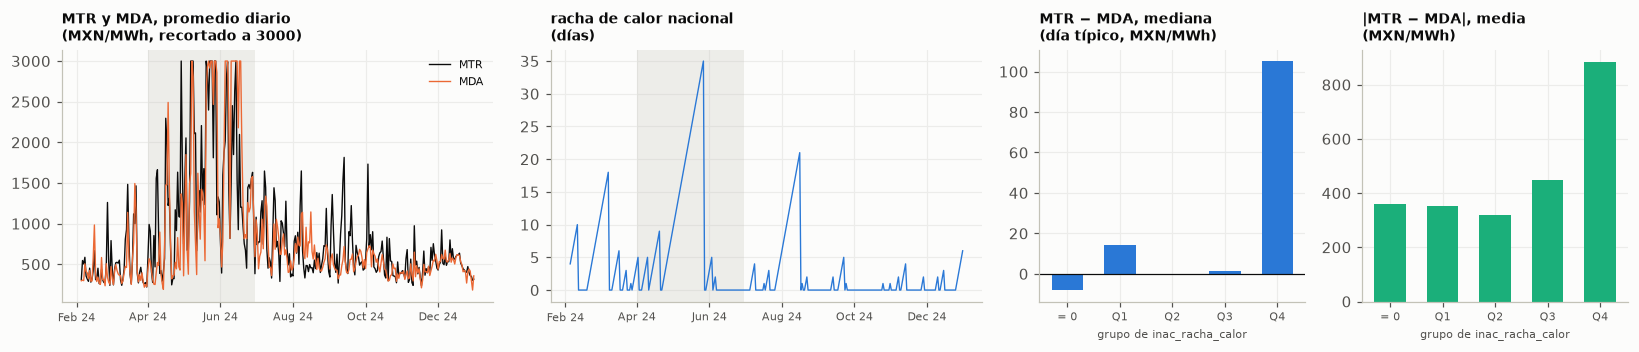

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
= 0,0 a 0,174,730.3,814.6,-84.3,-8.0,361.4,17.8
Q1,1 a 2,40,757.1,718.9,38.2,14.2,353.1,27.5
Q2,2 a 5,39,732.0,538.7,193.3,-0.6,317.3,23.1
Q3,5 a 12,39,892.7,695.2,197.6,1.3,447.7,35.9
Q4,12 a 35,39,1660.4,1553.6,106.9,105.2,885.1,46.2


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo  \
                            nivel MTR MTR − MDA |MTR − MDA|  nivel MTR   
inac_cdh24                       0.76      0.05        0.77       0.32   
inac_t_noche                     0.77     -0.11        0.78       0.34   
inac_cdh_3d                      0.74      0.00        0.75       0.29   
inac_cdh_anom28                  0.25      0.46        0.19       0.02   
inac_racha_calor                 0.26      0.42        0.18      -0.01   
inac_lluvia                      0.43     -0.31        0.45       0.27   
inac_nub_tarde                  -0.15     -0.02       -0.18       0.27   
inac_rev1                        0.18      0.11        0.16       0.11   
inac_rev_cdh                    -0.07      0.08       -0.08       0.02   
inac_err7_d2                    -0.13     -0.05       -0.07      -0.23   
inac_cdh_err7_d2                -0.34     -0.12       -0.25      -0.24   

                                        
                 MTR − MDA |MTR − MDA|  
inac_cdh24            0.02        0.58  
inac_t_noche         -0.01        0.59  
inac_cdh_3d          -0.05        0.55  
inac_cdh_anom28      -0.04        0.14  
inac_racha_calor     -0.15        0.19  
inac_lluvia          -0.04        0.43  
inac_nub_tarde       -0.02        0.35  
inac_rev1             0.15        0.15  
inac_rev_cdh          0.13        0.05  
inac_err7_d2         -0.02       -0.48  
inac_cdh_err7_d2      0.07       -0.48

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
inac_cdh24,0.06,0.01,-0.06,-0.02
inac_t_noche,-0.06,-0.11,-0.14,-0.10
inac_cdh_3d,0.00,-0.05,-0.09,-0.02
inac_cdh_anom28,0.27,0.15,0.05,0.10
inac_racha_calor,0.17,0.10,0.00,0.06
inac_lluvia,-0.18,-0.16,-0.12,-0.06
inac_nub_tarde,-0.03,0.02,0.08,0.01
inac_rev1,0.12,0.03,-0.02,0.02
inac_rev_cdh,0.09,-0.05,-0.03,0.08
inac_err7_d2,-0.01,-0.01,-0.01,0.00


promedios por grupo de inac_rev1:


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,-0.676 a -0.172,67,807.3,914.6,-107.3,-8.6,432.1,19.4
Q2,-0.168 a -0.0731,66,891.1,808.6,82.5,-1.9,409.9,22.7
Q3,-0.0723 a -0.00372,66,725.0,747.9,-22.9,-7.2,351.8,22.7
Q4,-0.00288 a 0.089,66,985.9,847.7,138.2,8.6,489.1,30.3
Q5,0.0899 a 0.56,66,903.7,897.8,5.9,4.2,452.3,30.3


promedios por grupo de inac_lluvia:


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,0 a 0.0335,67,578.2,490.4,87.8,2.5,221.2,11.9
Q2,0.0348 a 0.272,66,957.7,718.4,239.4,11.0,417.0,31.8
Q3,0.273 a 1.1,66,1198.7,1304.7,-106.1,-3.9,697.4,34.8
Q4,1.1 a 3.44,66,808.6,931.2,-122.5,-14.7,465.8,24.2
Q5,3.49 a 31.2,66,773.3,778.3,-5.0,-14.8,337.2,22.7


In [16]:
# Clima nacional como serie: índice ponderado por consumo, calor acumulado, rachas, lluvia y errores recientes del pronóstico
explorar(['inac_cdh24', 'inac_t_noche', 'inac_cdh_3d', 'inac_cdh_anom28', 'inac_racha_calor', 'inac_lluvia', 'inac_nub_tarde', 'inac_rev1', 'inac_rev_cdh',
          'inac_err7_d2', 'inac_cdh_err7_d2'], 'inac_racha_calor', 'racha de calor nacional', 'días', '03_g11_clima_nacional_serie.png')
for col in ('inac_rev1', 'inac_lluvia'):
    print(f'promedios por grupo de {col}:'); display(ex.quintiles(FX, O, col))

Se ve lo siguiente:
- **Nivel y magnitud:** el índice nacional repite lo de siempre. Calor, noche, lluvia y radiación acompañan al nivel del MTR (0.74–0.79 antes del desarrollo) y a la magnitud del error (0.55–0.59 en el desarrollo).
- **Calor acumulado:** la anomalía de calor y la racha tienen la relación más fuerte que se ha visto con la dirección **antes** del desarrollo (0.46 y 0.42). En los días con racha de 12 o más días, la mediana de la diferencia es **+105 MXN/MWh** y casi la mitad de los días tiene pico. Pero en el desarrollo la relación desaparece o se invierte (−0.04 y −0.15). Es la ola de calor de la primavera de 2024: un solo episodio.
- **La noche:** igual que la máxima del día, solo nivel.
- **Lluvia nacional:** antes del desarrollo, más lluvia va con un MTR por debajo del MDA (−0.31), y en el desarrollo casi nada (−0.04). Por quintiles, la mediana pasa de +11 a −15 entre los días secos y los muy lluviosos. El sentido es el esperado (lluvia → menos aire acondicionado → la demanda real queda por debajo de lo previsto), pero la señal es débil y se concentra en la primavera.
- **Revisión del último día:** es la única de este grupo con la misma dirección en los dos periodos, aunque pequeña (0.11 y 0.15). Si en la última corrida el pronóstico subió de temperatura, el MTR tiende a quedar por encima del MDA: mediana −9 en el quintil que bajó más y +4 a +9 en los que subieron. Su efecto se pierde si se retrasa un día (0.12 → 0.03), como corresponde a información nueva. La revisión de 3 a 2 días no dice nada (−0.05 y 0.06).
- **Error reciente del pronóstico:** no se relaciona con la dirección (−0.05 y −0.02). Su relación con la magnitud en el desarrollo (−0.48) es estacional: en invierno el pronóstico se equivoca distinto.

Tratar el clima como serie no cambia el panorama. La memoria del calor solo explica la primavera de 2024, y el error reciente del pronóstico no deja señal. Lo que se sostiene es la **revisión del último día** del índice nacional: es pequeña pero aparece en los dos periodos y pierde fuerza con el rezago, lo esperable de información que el MDA no alcanzó a ver por completo. Va a los modelos del notebook 07.

### 2.14 Días análogos
Una forma distinta de usar la historia: en vez de rezagos fijos, buscar los días pasados que más se parecen al día *d*. Para cada *d* se toman los 10 días con MTR ya publicado (hasta *d−8*) cuyo MDA (forma y nivel) y calor nacional pronosticado son más parecidos, y se mira qué hizo su MTR frente a su MDA: la mediana por hora de la diferencia, cuántos de ellos tuvieron pico y qué tan parecidos son en realidad.

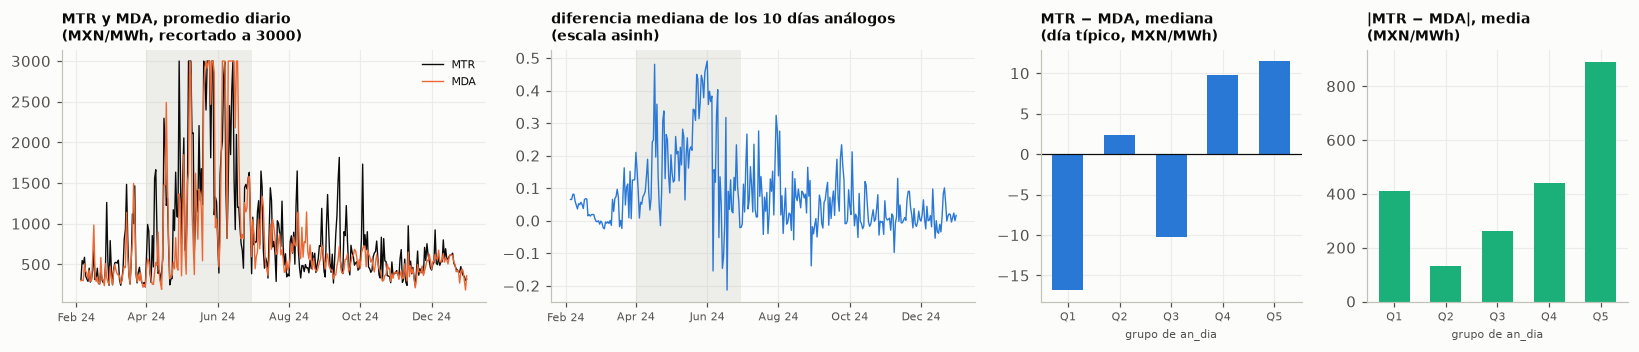

promedios por grupo de la feature clave (feb–dic 2024):


,rango de la feature,días,MTR medio,MDA medio,MTR − MDA medio,MTR − MDA mediana,|MTR − MDA| medio,% días con pico
Q1,-0.213 a -0.00301,67,750.5,887.9,-137.4,-16.8,410.8,16.4
Q2,-0.00245 a 0.0234,66,479.3,426.7,52.6,2.4,131.9,7.6
Q3,0.0237 a 0.0741,66,594.9,625.9,-31.0,-10.2,262.8,9.1
Q4,0.0745 a 0.151,66,956.9,810.6,146.2,9.8,438.9,36.4
Q5,0.152 a 0.491,66,1532.4,1466.0,66.5,11.5,891.3,56.1


correlación de Spearman con el nivel del MTR, la diferencia MTR − MDA y su magnitud:


antes del desarrollo                       desarrollo            \
                   nivel MTR MTR − MDA |MTR − MDA|  nivel MTR MTR − MDA   
an_dia                  0.51      0.22        0.45       0.19      0.09   
an_h19                 -0.12      0.03       -0.15       0.09      0.08   
an_h20                  0.15      0.39        0.07       0.16     -0.10   
an_pico                 0.82     -0.01        0.79       0.29     -0.12   
an_dist                 0.79     -0.14        0.78       0.51     -0.11   

                     
        |MTR − MDA|  
an_dia         0.21  
an_h19        -0.06  
an_h20         0.25  
an_pico        0.46  
an_dist        0.69

correlación con la diferencia si la feature llegara k días más tarde:


,+0 días,+1 días,+2 días,+7 días
an_dia,0.17,0.14,0.01,0.04
an_h19,0.05,-0.03,-0.05,-0.01
an_h20,0.12,0.09,0.03,0.07
an_pico,-0.03,-0.06,-0.16,-0.06
an_dist,-0.06,-0.07,-0.14,-0.01


In [17]:
# Días análogos: qué error tuvo el MDA en los días pasados más parecidos al que se pronostica
explorar(['an_dia', 'an_h19', 'an_h20', 'an_pico', 'an_dist'], 'an_dia', 'diferencia mediana de los 10 días análogos', 'escala asinh', '03_g12_analogos.png')

Resultados:
- **La diferencia de los análogos** tiene la misma dirección que la del día *d* en los dos periodos (0.22 y 0.09). Por quintiles, la mediana de la diferencia va de −17 en el grupo más bajo a +10 y +12 en los dos más altos.
- **Lo que más dicen los análogos es el riesgo, no la dirección.** La fracción de análogos con pico se relaciona con la magnitud del error (0.79 y 0.46). Cuando 6 o más de los 10 análogos tuvieron pico, el 62% de los días también lo tiene, contra 8% cuando ninguno lo tuvo.
- **Qué tan parecidos son:** la distancia promedio a los análogos se relaciona con la magnitud (0.69 en el desarrollo). Cuando no hay días parecidos, el error es grande; es una medida natural de "día raro".
- **Por hora** la señal es ruidosa: a las 20 h la correlación cambia de signo entre periodos (0.39 y −0.10).

Los análogos ordenan bien el **riesgo**: dicen qué días tienen alta probabilidad de pico y de error grande. Son un candidato natural para el clasificador de picos y los intervalos (notebook 09), más que para el pronóstico puntual. Su señal de dirección es pequeña y se debilita en el desarrollo. Van a los modelos del notebook 07 para ver si les sacan algo más.

## 3. Resumen de todas las fuentes

Se junta en una tabla la correlación más fuerte de cada fuente con cada objetivo, para ver el patrón de conjunto.

In [18]:
# Resumen: la correlación más fuerte de cada grupo con cada objetivo (variables diarias)
R = ex.correlaciones(FX, O, [col for col in FX.columns if not re.match(r'.*_h\d+$', col)])
R['grupo'] = GX.reindex(R.index)
res = R.groupby('grupo').agg(lambda s: s.abs().max()).round(2)
display(res); res.to_csv(REP / '03_resumen_correlaciones.csv')

antes del desarrollo                       desarrollo            \
                 nivel MTR MTR − MDA |MTR − MDA|  nivel MTR MTR − MDA   
grupo                                                                   
G10                   0.78      0.39        0.77       0.32      0.18   
G11                   0.79      0.46        0.79       0.34      0.15   
G12                   0.82      0.22        0.79       0.51      0.12   
G4                    0.87      0.40        0.87       0.60      0.16   
G5                    0.77      0.38        0.75       0.32      0.19   
G6                    0.64      0.37        0.63       0.32      0.18   
G6e                   0.72      0.14        0.69       0.34      0.14   
G6g                   0.65      0.35        0.68       0.35      0.10   
G7v                   0.31      0.06        0.31       0.19      0.23   
G8                    0.79      0.40        0.77       0.27      0.12   
G9                    0.80      0.35        0.79       0.35      0.25   

                   
      |MTR − MDA|  
grupo              
G10          0.23  
G11          0.59  
G12          0.69  
G4           0.68  
G5           0.56  
G6           0.51  
G6e          0.53  
G6g          0.53  
G7v          0.12  
G8           0.55  
G9           0.58

La tabla resume el capítulo. En todas las fuentes salvo las vacaciones, la correlación más fuerte con el **nivel** y con la **magnitud** del error es alta antes del desarrollo (0.6–0.9) y baja a la mitad en el desarrollo, porque la primavera de 2024 domina. Con la **diferencia**, que es lo que se pronostica, el máximo de cada grupo queda entre 0.10 y 0.25 en el desarrollo. Ninguna fuente pasa de ese nivel de forma estable, y la mayoría de esos máximos se deben a una o dos columnas que cambian de signo entre periodos.

Lo que sí se sostiene en los dos periodos, con el mismo signo, es poco, pero existe:

- el precio de tiempo real de ERCOT de *d−2* (−0.25 y −0.25),
- la anomalía de exportación de ERCOT a México (−0.14 y −0.24),
- el calor en la Ciudad de México (0.27 y 0.20),
- la congestión que el MDA prevé en el sureste, Oriente y Península (0.35/0.18 y 0.35/0.13), aunque concentrada en la primavera de 2024,
- la revisión del último día en el índice nacional de temperatura (0.11 y 0.15),
- la diferencia de los días análogos (0.22 y 0.09).

Las alertas de CENACE tienen la relación más fuerte con la dirección del error, pero solo existen en un episodio. Todas van a los modelos del notebook 07, que miden cuánto aporta cada familia.

## 4. Una pausa: ¿se eligieron mal las fuentes?

Hasta aquí casi todas las fuentes muestran una relación débil con la dirección del error (sección 3), y en el notebook 07 los combustibles y el clima aportan algo muy pequeño a LEAR y nada al gradient boosting. La pregunta obvia es si se eligieron mal las fuentes. Al repasar el contexto de la zona y del sistema, salen cuatro razones para que los combustibles aporten poco. Son hipótesis, y las exploraciones de la sección 2 y la celda de abajo las ponen a prueba:

1. **El MDA ya trae el precio del combustible.** El modelo no pronostica el nivel del MTR, sino su diferencia con el MDA. Esa diferencia nace de lo que cambia entre el día anterior y la operación real: la demanda sube más de lo previsto, falla una planta, el sol o el viento rinden distinto. El precio del gas casi no cambia en esas 24 horas.
2. **Henry Hub es el precio de gas equivocado.** El gas que llega al norte de México se cotiza en los centros de Texas (Waha, Houston Ship Channel, Agua Dulce). En 2024, Waha tuvo precio *negativo* en cerca de la mitad de las sesiones por falta de ductos en la Cuenca Pérmica ([Argus](https://www.argusmedia.com/es/news-and-insights/latest-market-news/2642762-viewpoint-permian-waiting-on-new-gas-lines)), totalmente desacoplado de Henry Hub. No se encontró una serie diaria gratuita de Waha, así que queda como limitación.
3. **La escala no da.** El gas se mueve centavos de dólar al día, mientras el error típico del MDA es de 200 a 300 MXN/MWh.
4. **El choque que importa es de cantidad, no de precio.** Cuando una helada congela pozos en Texas, el problema es que el gas no llega, como en febrero de 2021 o en enero de 2024, cuando CENACE declaró emergencia. Eso se anticipa mejor con la temperatura pronosticada en Texas que con el precio del gas de hace dos días.

Del contexto local salen dos cosas más. La carga más grande de la zona, **AHMSA** (nodo 06AHM-400), no produce acero desde finales de 2023 y fue declarada en quiebra en noviembre de 2024 ([Milenio](https://amp.milenio.com/estados/subasta-de-ahmsa-define-el-destino-de-monclova)). Eso cambia la congestión local, pero no la energía, que es donde está el error (notebook 02). Además, las **emergencias y alertas de CENACE** de mayo de 2024 coinciden con los picos más grandes de la muestra.

De aquí salieron las fuentes de las secciones 2.5 a 2.7, todas con su regla de disponibilidad y bajo la misma prueba de no-fuga:

- **Clima de Monterrey y de Texas:** calor en Monterrey, la carga grande del Noreste; calor en San Antonio (demanda de Texas); heladas en San Antonio y Midland (Cuenca Pérmica).
- **Estados operativos del sistema:** una tabla armada a mano en `data/external/estados_operativos.csv`, con la fuente de cada fila. Se usa el estado de *d−2*, porque al mediodía de *d−1* todavía no se sabe si habrá alerta esa tarde.
- **Índice de vacaciones:** el calendario escolar real de la SEP, con Semana Santa, fin de año, feriados y puentes, en una escala de 0 a 1. Corrige un error del calendario anterior, que marcaba la semana *después* de Pascua y no las vacaciones de Semana Santa.

In [19]:
# Dos comprobaciones: (1) el gas se relaciona con el nivel del MDA pero no con su error; (2) cuántos eventos raros
# (heladas en Texas, alertas, vacaciones) caen en cada periodo
Fm, _ = f2.construir(c, ['G2', 'G4', 'G6']); Yt, Xt = f2._t(c)
sp_m = (Yt - Xt).mean(axis=1).loc[Fm.index]
cor = pd.DataFrame({'nivel del MDA (promedio del día)': [Fm.mda_m.corr(Fm.hh_spot), Fm.mda_m.corr(Fm.hh_spot_d7)],
                    'MTR − MDA (promedio del día)': [sp_m.corr(Fm.hh_spot), sp_m.corr(Fm.hh_spot_d7)]},
                   index=['Henry Hub (nivel)', 'Henry Hub (cambio en 7 días)']).round(2)
display(cor)
Fn, _ = f2.construir(c, ['G7v', 'G8'])
per = {'entrenamiento previo (feb–jun 2024)': slice(f2.TRAIN_START, '2024-06-30'), 'desarrollo (jul–dic 2024)': slice(f2.DEV_INI, f2.DEV_FIN),
       'test (ene–jun 2025)': slice(f2.TEST_INI, f2.TEST_FIN)}
cob = pd.DataFrame({k: {'días con helada en Texas': int(Fn.loc[s, 'tx_helada'].sum()), 'días con alerta o emergencia (d−2)': int((Fn.loc[s, 'eo_d2'] > 0).sum()),
                        'días de vacaciones SEP': int(Fn.loc[s, 'vac_sep'].sum()), 'Tmax media en Monterrey (°C)': round(Fn.loc[s, 'mty_tmax'].mean(), 1)}
                    for k, s in per.items()})
display(cob)

,nivel del MDA (promedio del día),MTR − MDA (promedio del día)
Henry Hub (nivel),0.24,-0.16
Henry Hub (cambio en 7 días),0.14,-0.00


,entrenamiento previo (feb–jun 2024),desarrollo (jul–dic 2024),test (ene–jun 2025)
días con helada en Texas,1.0,0.0,21.0
días con alerta o emergencia (d−2),7.0,0.0,0.0
días de vacaciones SEP,12.0,53.0,19.0
Tmax media en Monterrey (°C),32.1,29.5,29.4


Las dos tablas explican por qué estas fuentes aportan poco.

La primera apoya la hipótesis 1, con un matiz. El *cambio* semanal de Henry Hub tiene algo de relación con el nivel del MDA (0.14) y ninguna con la diferencia entre MTR y MDA (0.00), que es lo que se pronostica: cuando el gas se mueve, el MDA ya lo refleja. El *nivel* sí aparece algo relacionado con la diferencia MTR − MDA (−0.16), pero con signo contrario al esperado. Lo más probable es que sea estacional: el gas estuvo barato en la primavera de 2024, justo cuando el MTR se disparó por la ola de calor. No es una señal que el modelo pueda usar de forma estable.

La segunda muestra un límite que no se había visto con esta claridad. **Los eventos raros caen en un solo periodo.** Las heladas de Texas aparecen solo en el test (enero y febrero de 2025), y las alertas de CENACE solo en el entrenamiento (mayo de 2024). Ni el desarrollo ni el modelo ven variación de esas variables donde la necesitan. Con 17 meses de datos, una variable con sentido físico puede no servir aunque sea correcta, simplemente porque el evento no se repite. Las vacaciones, en cambio, sí aparecen en los tres periodos.

## 5. ¿Qué otra información pública existe el día anterior?

Antes de cerrar la lista de exógenas se revisa qué más publica alguien a tiempo para usarlo en *d−1*. La pregunta es siempre la misma: ¿se conoce antes del mediodía de *d−1* y trae algo que el MDA no sabía al cerrarse?

| Fuente | ¿Qué da? | ¿Disponible al emitir? | Decisión |
|---|---|---|---|
| CENACE, *Estimación de la Demanda Real* ([SIM](https://www.cenace.gob.mx/Paginas/SIM/Reportes/EstimacionDemandaReal.aspx)) | demanda horaria del SEN por balance y por retiros | **no**: se publica unos 14 días después (en el portal, el día de operación 11/10 aparece publicado el 25/10). Llega más tarde que el MTR | descartada |
| CENACE, reporte semanal del MEM | despacho por tipo de oferta y carga semanal del MTR | no: rezago semanal | descartada |
| CENACE, gráfica de demanda en tiempo real | demanda neta nacional en vivo y pronóstico del pico | sí, en vivo, pero **sin histórico descargable** | solo serviría registrándola desde hoy; no se puede evaluar |
| EIA-930 de ERCOT | demanda real, generación por combustible, intercambio con CENACE | sí: *d−2* completo | **incluida** (sección 2.8) |
| ERCOT, precio RT (NP6-785) | precio de tiempo real por hub y zona | sí: *d−2* completo y *d−1* hasta las 11:00. El mercado de día siguiente de ERCOT para *d* sale después del mediodía, así que no se usa | **incluida** (sección 2.9) |
| Open-Meteo, clima nacional (Previous Runs) | pronósticos con 48 y 72 h de anticipación | sí | **incluida** (sección 2.10) |
| Open-Meteo, *Single Runs* (ECMWF por corrida exacta) | el pronóstico de una corrida específica | sí, pero solo desde marzo de 2024 y sin corridas posteriores al cierre del MDA y anteriores al mediodía | no aporta frente a lo anterior |
| CENAGAS, alertas críticas del SISTRANGAS | restricción de gas natural | sí, pero son rarísimas (febrero de 2021, un aviso preventivo en enero de 2024) | mismo problema que las alertas de CENACE: no se repiten |
| Waha, Houston Ship Channel | precio diario del gas en Texas | solo de pago (NGI, Platts) | limitación |
| CENACE, PML de otros nodos (SW-PML) | MDA de *d* y MTR hasta *d−8* de 31 nodos de la red, con sus componentes | sí, con las mismas reglas que Monclova | **incluida** (secciones 2.11 y 2.12) y como datos extra de entrenamiento (notebook 07) |
| CENACE, Catálogo de NodosP ([SIM](https://www.cenace.gob.mx/Paginas/SIM/NodosP.aspx)) | claves, zona de carga, región y tensión de cada nodo | catálogo fijo | usado para elegir los 31 nodos |
| Batu Energy, Atlas ([sitio](https://batuenergy.com/atlas)) | centrales, subestaciones, consumo y usuarios de CFE por división, generación distribuida, precios del MDA | catálogos fijos y series anuales o semestrales; los precios son de un solo día (24/06/2026) | el consumo por división se usa como **peso** del índice nacional de clima (sección 2.13); las centrales, para interpretar la red; nada sirve como variable diaria |
| Open-Meteo, índice nacional (14 ciudades, Previous Runs) | temperatura, lluvia, nubosidad y radiación con 4, 3 y 2 días de anticipación, y lo observado | sí; lo observado hasta *d−2* | **incluida** (sección 2.13) |
| CONAGUA, almacenamiento de presas (SINA/SIH) | nivel de las presas del Grijalva (hidroeléctricas) | el portal no responde a descargas automáticas (redirige a sí mismo); solo hay reportes semanales en PDF | no se pudo usar; además cambia lento frente a un error diario |

La conclusión es incómoda pero importante. **Lo que más ayudaría no es público a tiempo.** El pronóstico de demanda y de renovables de CENACE y la demanda real reciente de México llegan después que el propio MTR o no se publican. Lo que sí está disponible en *d−1* viene de Texas o del clima, y llega al mismo tiempo que lo que ya incorporó el MDA.

## 6. Comprobación de que no hay información del futuro

Cada grupo se construye con rezagos explícitos, y además se comprueba de forma automática. Se reemplaza por basura todo lo que no existiría al emitir el pronóstico del día *d*: MTR posterior a *d−8*, MDA posterior a *d*, clima posterior a lo pronosticado, FRED y EIA posteriores a su publicación. Si la fila de features del día *d* cambia, hay una fuga. Se incluye un control positivo, una feature con fuga deliberada (el MTR de *d−7*), para comprobar que la prueba sí la detecta. La misma prueba corre en `tests/test_features2.py`.

In [20]:
# Prueba de fuga: se pone basura en todo lo que no existiría al emitir el pronóstico del día d y se comprueba que las
# variables de ese día no cambian. Después, un control positivo: un grupo con fuga deliberada SÍ debe cambiar
grupos = ['G0', 'G0dow', 'G1', 'G2', 'G4', 'G5', 'G6', 'G6g', 'G6e', 'G7', 'G7v', 'G8', 'G9', 'G10', 'G11', 'G12']
res = []
for d in ['2024-03-15', '2024-09-10', '2025-02-20']:
    d = pd.Timestamp(d)
    for lag in (2, 8):
        cl = replace(c, lag_precios=lag); Fa, _ = f2.construir(cl, grupos)
        Fp, _ = f2.construir(replace(f2.perturbar(cl, d), dias=pd.DatetimeIndex([d])), grupos)
        res.append({'día': d.date(), 'rezago de precios': lag, 'columnas': Fa.shape[1],
                    'columnas que cambian': int((~np.isclose(Fa.loc[d].values.astype(float), Fp.loc[d].values.astype(float), equal_nan=True)).sum())})
display(pd.DataFrame(res))
def g_fuga(cc): Yt_, _ = f2._t(cc); return f2._ix(f2._sh(Yt_, 7, 'fuga_l7'), cc)
f2.GRUPOS['GFUGA'] = (g_fuga, 'fuga deliberada')
d = pd.Timestamp('2024-09-10')
Fa, _ = f2.construir(c, ['GFUGA']); Fp, _ = f2.construir(replace(f2.perturbar(c, d), dias=pd.DatetimeIndex([d])), ['GFUGA'])
print('control positivo (MTR de d−7): cambian', int((~np.isclose(Fa.loc[d].values.astype(float), Fp.loc[d].values.astype(float))).sum()), 'de', Fa.shape[1], 'columnas')
del f2.GRUPOS['GFUGA']

,día,rezago de precios,columnas,columnas que cambian
0,2024-03-15,2,598,0
1,2024-03-15,8,598,0
2,2024-09-10,2,598,0
3,2024-09-10,8,598,0
4,2025-02-20,2,598,0
5,2025-02-20,8,598,0


control positivo (MTR de d−7): cambian 24 de 24 columnas


Ninguna columna cambia en las fuentes reales, y las 24 del control con fuga sí cambian. La prueba es capaz de detectar una fuga, y no encuentra ninguna.

## Resumen del notebook

- **Casi todo se relaciona con *cuánto* se equivoca el MDA y casi nada con *hacia dónde*.** El calor, la demanda de Texas o el precio del gas acompañan al nivel del precio y al tamaño del error, pero el MDA ya los sabe. No dicen si el tiempo real saldrá por encima o por debajo.
- **Lo poco que apunta a la dirección y se repite en los dos periodos** está cerca del precio nacional del día: el precio reciente de Texas en tiempo real, la exportación de Texas a México fuera de lo normal, el calor en la Ciudad de México, la congestión que el MDA prevé hacia el sureste, el último cambio del pronóstico de clima del país y lo que hicieron los días más parecidos del pasado. Todas son relaciones pequeñas (correlaciones de 0.1 a 0.35): poco, pero no nada, y vale la pena explorarlas un rato sin invertir demasiado.
- **Las alertas de CENACE tienen la relación más fuerte con la dirección, pero ocurren en un solo episodio.** Con 17 meses de datos, una variable correcta puede no servir solo porque su evento no se repite. Lo mismo pasa con las heladas de Texas, que solo caen en el test.
- **Lo que más ayudaría no es público a tiempo:** el pronóstico de demanda y de renovables de CENACE, o la demanda real reciente de México.
- **Cada fuente aporta poco, y lo poco que suma cuenta.** Lo que pesa de verdad es cómo cambia el precio en el tiempo y cómo se equivoca el MDA (notebook 07); modelar las fuentes externas es secundario frente a eso.
- **Los otros nodos de la red** no aportan información nueva de la energía, porque la energía es la misma en todos. Sí aportan su congestión, y el notebook 07 los usa de otra manera: como más ejemplos para entrenar.

Cada fuente tiene una regla de disponibilidad explícita y verificada, y todos los modelos entrenan desde el 5 de febrero de 2024. El notebook 07 mide si un modelo les saca provecho.